In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
from pylab import *
from numpy import pi
from spylind import spyIVP as so
import sympy as sm;
import pdb
sm.init_printing()
import co_mag_model as m
import fit_stats as fs
import matplotlib

plt.style.use('dark_background')
#plt.style.use('default')

font = {
        'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 14}

matplotlib.rc('font', **font)

pltColors = rcParams['axes.prop_cycle'].by_key()['color'] 


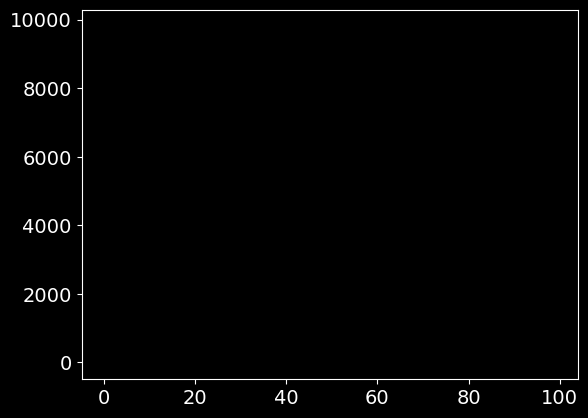

In [2]:
from matplotlib.collections import LineCollection


def plot_varying_alphas(x,y, alphas, ax=None, color='k', **kwargs):
    points = np.vstack([x,y]).T.reshape(-1,1,2)
    segments = np.hstack((points[:-1], points[1:]))
    if ax is None:
        fig, ax = plt.subplots()
    for segment, alpha in zip(segments[::1], alphas):
        plt.plot(*segment.T, alpha=alpha,color=color,**kwargs)

def plot_speed_alphas(x,y, ax=None, color='k', alpha_coeff=0.5,**kwargs):
    points = np.vstack([x,y]).T.reshape(-1,1,2)
    dLs = np.sqrt(np.sum((points[:-1] - points[1:])**2, axis = -1))[:,0]
    alphas = 1/dLs**alpha_coeff
    alphas/=alphas.max()
    segments = np.hstack((points[:-1], points[1:]))
    if ax is None:
        fig, ax = plt.subplots()
    for segment, alpha in zip(segments[::1], alphas):
        plt.plot(*segment.T, alpha=alpha,color=color,**kwargs)

#plot_varying_alphas(np.arange(100), np.arange(100)**2, np.sin(np.arange(100)/5)/2 +0.5)
plot_speed_alphas(np.arange(100), np.arange(100)**2)

#lc = LineCollection(segments, color = 'k', alpha=0.5,  lw=3)
#line = ax.add_collection(lc)
#plt.show()


In [3]:
d_dtD = m.get_d_dtDs()
alk_dt = d_dtD['alk']
nob_dt = d_dtD['nob']


In [4]:
state_syms = sm.Matrix( list(alk_dt[0]) + list(nob_dt[0]))
d_dt= sm.Matrix( list(alk_dt[1]) + list(nob_dt[1]))


In [5]:
state_syms, d_dt


⎛⎡P_x__e⎤  ⎡Ω_y⋅P_z__e - Ω_z⋅P_y__e - P_x__e⋅(R_{sd}__e + R_{se}__{en} + Rₚ) + ↪
⎜⎢      ⎥  ⎢                                                                   ↪
⎜⎢P_y__e⎥  ⎢ -Ωₓ⋅P_z__e + Ω_z⋅P_x__e - P_y__e⋅(R_{sd}__e + R_{se}__{en} + Rₚ)  ↪
⎜⎢      ⎥  ⎢                                                                   ↪
⎜⎢P_z__e⎥  ⎢ Ωₓ⋅P_y__e - Ω_y⋅P_x__e - P_z__e⋅(R_{sd}__e + R_{se}__{en} + Rₚ) + ↪
⎜⎢      ⎥, ⎢                                                                   ↪
⎜⎢ Pⁿₓ  ⎥  ⎢       Ω_y⋅P_z__n - Ω_z⋅P_y__n + P_x__e⋅R_{se}__{ne} - Pⁿₓ⋅R_{dec} ↪
⎜⎢      ⎥  ⎢                                                                   ↪
⎜⎢P_y__n⎥  ⎢        -Ωₓ⋅P_z__n + Ω_z⋅Pⁿₓ + P_y__e⋅R_{se}__{ne} - P_y__n⋅R_{dec ↪
⎜⎢      ⎥  ⎢                                                                   ↪
⎝⎣P_z__n⎦  ⎣                  Ωₓ⋅P_y__n - Ω_y⋅Pⁿₓ + P_z__e⋅R_{se}__{ne} - P_z_ ↪

↪  Pⁿₓ⋅R_{se}__{en} + Rₘ⋅s_x__m + Rₚ⋅s_x__p + γₑ⋅(-P_y__e⋅(B_z + Mₙ⋅P_z__n⋅λ + ↪
↪                          

In [6]:
s = m.s


In [7]:
subD =  dict( zip(s.Om_v[1:], [0,0]) )  \
        |dict( zip(s.sp_v, [0,0,1]) ) \
        |dict( zip(s.anom_e_v, [0,0,0]) ) \
        |dict( zip(s.sm_v, [0,0,0]) )\
        | {s.B_v[2] : s.Bbias,
           }\
        |{s.anom_n_v[0]:0, s.anom_n_v[1]:0 } # don't set Beta[2]- it's for necom pulses 


        
constantsD = {
    #s.y_n : .00336*2*np.pi,#.0324*2*pi, #Hz/nT 0.011 0.0324
    s.y_n : .0324*2*np.pi,#.0324*2*pi, #Hz/nT 0.011 0.0324

    s.R_n_sd : 1e-10, #/s
    s.R_n_dec : .1,
    s.y_e : 7*2*np.pi, #Hz/nT
    s.R_e_sd : 50, #/s
    s.Rm :0,
    s.lam: 1,
    s.Me: 9,
    s.Mn: 100*5,
    s.R_ne_se: 0,
    s.R_en_se: 0,
} 


In [9]:

subD |= constantsD
evoD = {sym:d_dt for sym,d_dt in zip(state_syms, d_dt.subs(subD))}

#bias_ax = 200*np.linspace(0,1,5)**1.5
#bias_ax -= bias_ax[0] + (bias_ax[1]-bias_ax[0])/2
#bias_ax = np.hstack([-bias_ax[::-1], bias_ax])
#bias_ax = -np.array([100, 150,200, 250], dtype='f8')
bias_ax = -np.linspace(50, 150, 50)
ind = int(np.argmin(np.abs(-bias_ax - 106.25)))
#bias_ax = -np.linspace(370, 460, 30)
ode_s = so.ODESys(evoD, tSym = s.t, trans_dims={s.Bbias:bias_ax}, driving_syms=[ s.Rp, s.anom_n_v[2], s.Om_v[0], s.B_v[0],s.B_v[1] ])
ode_s.set_initial_state(np.array([0,0.,0,  0, 0, 0.2])) 
#ode_s.set_constants({T1:10, T2:20, Rx:0, Ry:0})

ode_s.summary()


**Function signatures:**

state_dep_f( $\displaystyle t$, dimAxes = $[ \displaystyle B_{bias} ]$, state = $[ \displaystyle P^{e}_{x}, \displaystyle P^{e}_{y}, \displaystyle P^{e}_{z}, \displaystyle P^{n}_{x}, \displaystyle P^{n}_{y}, \displaystyle P^{n}_{z} ]$, driving= $[ \displaystyle R_{p}, \displaystyle \beta_{n z}, \displaystyle \Omega_{x}, \displaystyle B_{x}, \displaystyle B_{y} ]$, intermediate = $[  ]$ )

output_f( $\displaystyle t$, dimAxes = $[ \displaystyle B_{bias} ]$, state = $[ \displaystyle P^{e}_{x}, \displaystyle P^{e}_{y}, \displaystyle P^{e}_{z}, \displaystyle P^{n}_{x}, \displaystyle P^{n}_{y}, \displaystyle P^{n}_{z} ]$, driving= $[ \displaystyle R_{p}, \displaystyle \beta_{n z}, \displaystyle \Omega_{x}, \displaystyle B_{x}, \displaystyle B_{y} ]$, state_dependent= $[  ]$ , intermediate = $[  ]$ )

**Variables:**

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [12]:
tau = 0.02
ode_s.set_driving({
                   s.Rp:m.make_repeating_pulse_func(period= tau,rel_width=0.05, pulse_area=10),
                   s.anom_n_v[2]:m.make_alternating_pulse_func(period=tau, rel_width=0.05, pulse_area=1*pi/2, gamma = constantsD[s.y_n]),
                   s.B_v[0]: 1e-4,
                    s.B_v[1]: 0e-4,
                   s.Om_v[0]:0e-4,
                  })
model = ode_s.setup_model(solver_opts={'max_step': 0.00025})
tEnd = 5
startSteps = np.arange(0, 2*tau, 0.00001)
tSteps = np.arange(2*tau, tEnd, 0.005)
endSteps = tEnd+np.arange(0,2*tau, 0.00001)
tSteps = np.hstack([startSteps, tSteps, endSteps ])
tSteps_nec = tSteps.copy()
%time res_nec_b =model.integrate(tSteps)
endSlc = slice(-len(endSteps),None)
startSlc = slice(0,len(startSteps),None)




CPU times: user 9.97 s, sys: 4.69 ms, total: 9.98 s
Wall time: 10.1 s
CPU times: user 10.7 s, sys: 2.89 ms, total: 10.7 s
Wall time: 10.8 s


### Demonstrating Different Backends

Spylind supports multiple integration backends via `setup_model(backend='backend_name')`:
1. **NumPy/SciPy (`backend='numpy'`)**: Robust, standard CPU integration using SciPy's `ode` solver.
2. **Diffrax/JAX (`backend='diffrax'`)**: High-performance, JIT-compiled integration (XLA accelerated, ideal for large ensembles).
3. **CyRK (`backend='cyrk'`)**: Cythonized Runge-Kutta solver for fast CPU execution.

Here we show how to set up and solve the same system using each backend:

In [14]:
# 1. NumPy/SciPy (Default CPU Backend)
model_np = ode_s.setup_model(backend='numpy', solver_opts={'max_step': 0.00025}, bForceStateDimensions=False)
print("Integrating with NumPy backend...")
%time res_np = model_np.integrate(tSteps)

# 2. Diffrax (JAX / JIT Backend)
try:
    model_dx = ode_s.setup_model(backend='diffrax', solver_opts={'max_step': 0.00025}, bForceStateDimensions=False)
    print("Integrating with Diffrax backend...")
    %time res_dx = model_dx.integrate(tSteps)
    print("Diffrax integration successful. Shape:", res_dx.shape)
except Exception as e:
    print("Diffrax backend not available or failed:", e)

# 3. CyRK (Cython Backend)
try:
    model_cy = ode_s.setup_model(backend='cyrk', solver_opts={'max_step': 0.00025}, bForceStateDimensions=False)
    print("Integrating with CyRK backend...")
    %time res_cy = model_cy.integrate(tSteps)
    print("CyRK integration successful. Shape:", res_cy.shape)
except Exception as e:
    print("CyRK backend not available or failed:", e)


Integrating with NumPy backend...
CPU times: user 10.7 s, sys: 4.84 ms, total: 10.7 s
Wall time: 10.8 s
Integrating with Diffrax backend...
CPU times: user 30.2 ms, sys: 7.88 ms, total: 38.1 ms
Wall time: 49.6 ms
Diffrax backend not available or failed: Attempted boolean conversion of traced array with shape bool[].
The error occurred while tracing the function _fn at /home/morgan/miniforge3/envs/pmsim/lib/python3.14/site-packages/equinox/_eval_shape.py:31 for jit. This concrete value was not available in Python because it depends on the value of the argument _dynamic[1][0].
See https://docs.jax.dev/en/latest/errors.html#jax.errors.TracerBoolConversionError
Integrating with CyRK backend...
CPU times: user 23.9 s, sys: 8.86 ms, total: 23.9 s
Wall time: 24.3 s
CyRK integration successful. Shape: (8992, 6, 50)


In [128]:
tau = 0.02
ode_s.set_driving({
                   s.Rp:m.make_repeating_pulse_func(period= tau,rel_width=0.05, pulse_area=10),
                   s.anom_n_v[2]:m.make_alternating_pulse_func(period=tau, rel_width=0.05, pulse_area=0*pi/2, gamma = constantsD[s.y_n]),
                   s.B_v[0]: 1e-4,
                    s.B_v[1]: 0e-4,
                   s.Om_v[0]:0e-4,
                  })
model = ode_s.setup_model(solver_opts={'max_step': 0.00025}, bForceStateDimensions=False)
tEnd = 40
tSteps = np.arange(0, tEnd, 0.005)
endSteps = tEnd+np.arange(0,2*tau, 0.00001)
tSteps = np.hstack([tSteps, endSteps ])
%time res_pul_b =model.integrate(tSteps)
endSlc = slice(-len(endSteps),None)


ode_s.set_driving({
                   s.Rp:m.make_repeating_pulse_func(period= tau,rel_width=0.05, pulse_area=10),
                   s.anom_n_v[2]:m.make_alternating_pulse_func(period=tau, rel_width=0.05, pulse_area=0*pi/2, gamma = constantsD[s.y_n]),
                   s.B_v[0]: 0e-4,
                    s.B_v[1]: 0e-4,
                   s.Om_v[0]:1e-4,
                  })
model = ode_s.setup_model(solver_opts={'max_step': 0.00025}, bForceStateDimensions=False)
%time res_pul_om =model.integrate(tSteps)
#results_alk/= (bias_ax[None,None]*1e-4)


CPU times: user 1min 55s, sys: 1.32 s, total: 1min 56s
Wall time: 1min 55s
CPU times: user 2min 15s, sys: 2.08 s, total: 2min 17s
Wall time: 2min 14s


In [129]:

#results_alk/= (bias_ax[None,None]*1e-4)
ode_s.set_driving({
                   s.Rp:constantsD[s.R_e_sd],#m.make_repeating_pulse_func(period= tau,rel_width=0.05, pulse_area=0),
                   s.anom_n_v[2]:0,#m.make_alternating_pulse_func(period=tau, rel_width=0.05, pulse_area=0*pi/2, gamma = constantsD[s.y_n]),
                   s.B_v[0]: 0e-4,
                    s.B_v[1]: 0e-4,
                   s.Om_v[0]:1e-4,
                  })
model = ode_s.setup_model(solver_opts={'max_step': 0.00025}, bForceStateDimensions=False)
%time res_cw_om =model.integrate(tSteps)


#results_alk/= (bias_ax[None,None]*1e-4)
ode_s.set_driving({
                   s.Rp:constantsD[s.R_e_sd],#m.make_repeating_pulse_func(period= tau,rel_width=0.05, pulse_area=0),
                   s.anom_n_v[2]:0,#m.make_alternating_pulse_func(period=tau, rel_width=0.05, pulse_area=0*pi/2, gamma = constantsD[s.y_n]),
                   s.B_v[0]: 1e-4,
                    s.B_v[1]: 0e-4,
                   s.Om_v[0]:0e-4,
                  })
model = ode_s.setup_model(solver_opts={'max_step': 0.00025}, bForceStateDimensions=False)
%time res_cw_b =model.integrate(tSteps)

#results_alk/= (bias_ax[None,None]*1e-4)
#results_alk/= (bias_ax[None,None]*1e-4)


CPU times: user 18.9 s, sys: 316 ms, total: 19.2 s
Wall time: 19 s
CPU times: user 48.3 s, sys: 646 ms, total: 48.9 s
Wall time: 48.4 s


In [130]:
if 1:
    from copy import deepcopy
    ode_s_ = so.ODESys(evoD, tSym = s.t, trans_dims={s.Bbias:np.array([0])}, driving_syms=[ s.Rp, s.anom_n_v[2], s.Om_v[0], s.B_v[0],s.B_v[1] ])
    ode_s_.set_initial_state(np.array([0,0.,0,  0, 0, 0.0])) 
    ode_s_.set_driving({
                   s.Rp:constantsD[s.R_e_sd],#m.make_repeating_pulse_func(period= tau,rel_width=0.05, pulse_area=0),
                   s.anom_n_v[2]:0,#m.make_alternating_pulse_func(period=tau, rel_width=0.05, pulse_area=0*pi/2, gamma = constantsD[s.y_n]),
                   s.B_v[0]: 1e-4,
                    s.B_v[1]: 0e-4,
                   s.Om_v[0]: 0e-4,
                  })
    model = ode_s_.setup_model(solver_opts={'max_step': 0.00025}, bForceStateDimensions=False)
    %time res_cw_alk =model.integrate(tSteps)[endSlc,:, 0]
    #ode_s.set_constants({T1:10, T2:20, Rx:0, Ry:0})
    


CPU times: user 13.3 s, sys: 166 ms, total: 13.5 s
Wall time: 13.3 s


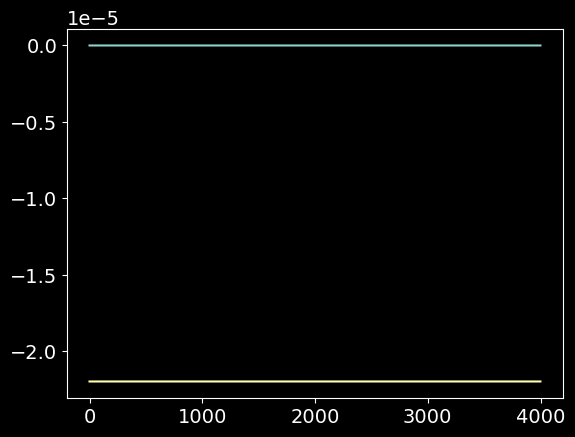

In [131]:
plt.plot(res_cw_alk[:,:2])


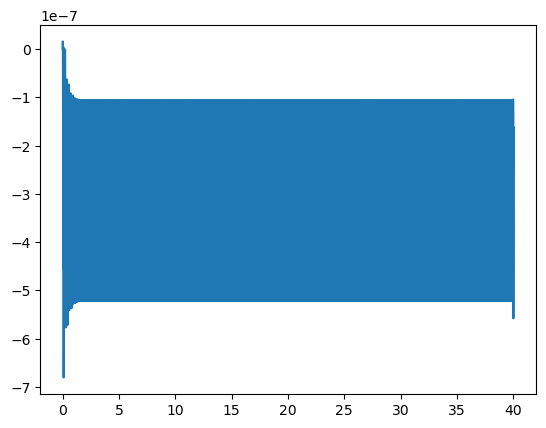

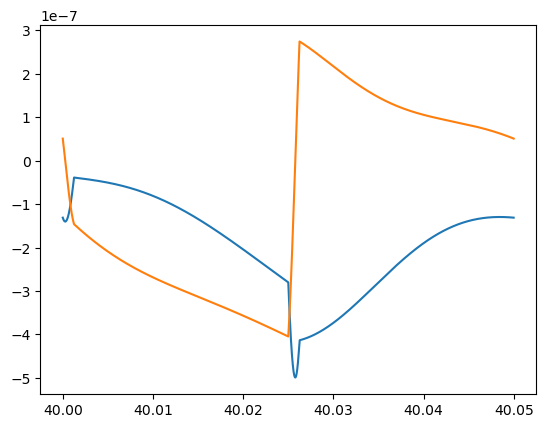

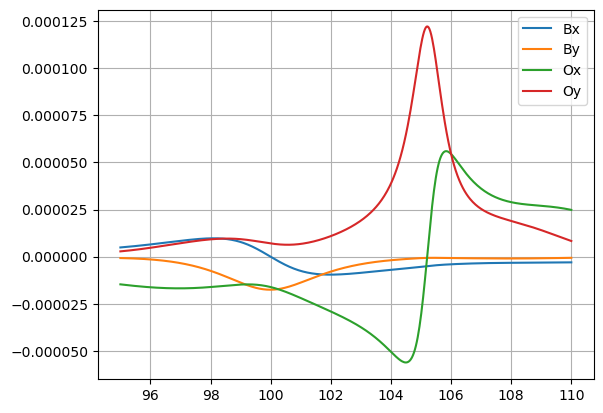

In [10]:
#endSlc = slice(-len(endSteps),None)

plt.plot(tSteps_nec[:], res_nec_om[:,3,10])
plt.figure()
#plt.plot(tSteps_nec[endSlc], res_nec_om[endSlc,1,50])
plt.plot(tSteps_nec[endSlc], res_nec_om[endSlc,3:5,50])

plt.figure()
#plt.plot(-bias_ax,res_nec_om[endSlc,1,:].mean(axis=0))
plt.plot(-bias_ax,res_nec_b[endSlc,:2,:].mean(axis=0).T)
plt.plot(-bias_ax,res_nec_om[endSlc,:2,:].mean(axis=0).T)
plt.grid()
plt.legend(['Bx', 'By', 'Ox', 'Oy'])


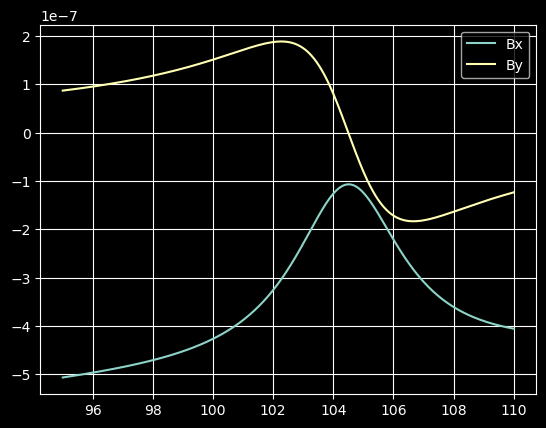

In [13]:

plt.figure()
#plt.plot(-bias_ax,res_nec_om[endSlc,1,:].mean(axis=0))
plt.plot(-bias_ax,res_cw_b[endSlc,:2,:].mean(axis=0).T)
#plt.plot(-bias_ax,res_nec_om[endSlc,:2,:].mean(axis=0).T)
plt.grid()
plt.legend(['Bx', 'By', 'Ox', 'Oy'])


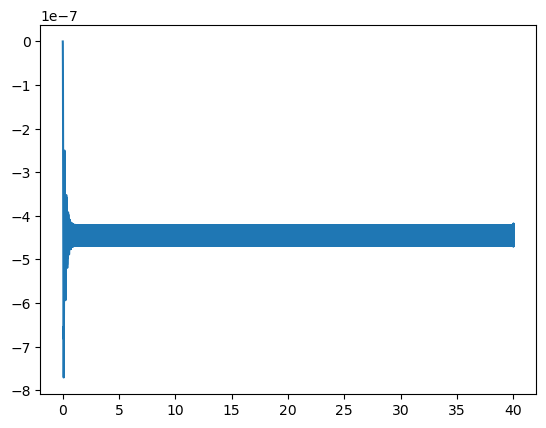

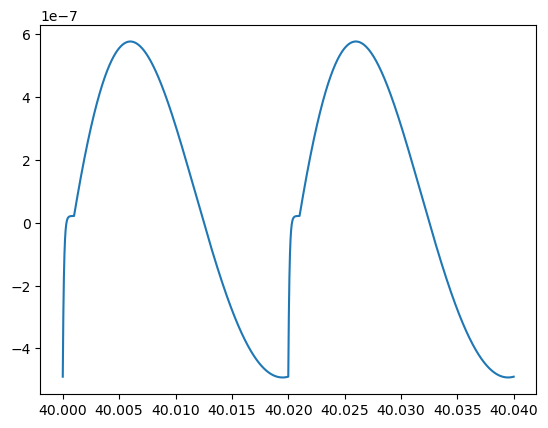

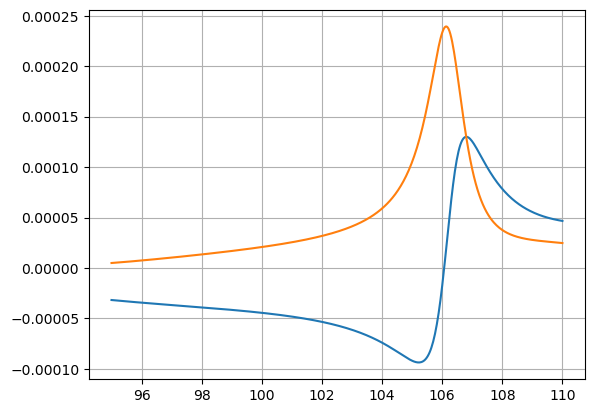

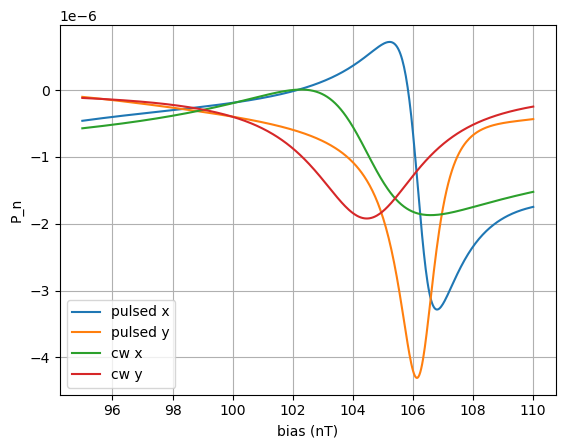

In [122]:
plt.plot(tSteps_nec[:], res_nec_om[:,3,10])
plt.figure()
plt.plot(tSteps_nec[endSlc], res_nec_b[endSlc,1,10])
plt.figure()
#plt.plot(-bias_ax,res_nec_om[endSlc,1,:].mean(axis=0))
plt.plot(-bias_ax,res_nec_om[endSlc,:2,:].mean(axis=0).T)
plt.grid()
plt.figure()
#plt.plot(-bias_ax,res_nec_om[endSlc,1,:].mean(axis=0))
plt.plot(-bias_ax,res_nec_om[endSlc,3:5,:].mean(axis=0).T)
plt.plot(-bias_ax,res_cw_om[endSlc,3:5,:].mean(axis=0).T)
plt.xlabel('bias (nT)')
plt.ylabel('P_n')
plt.legend(["pulsed x", "pulsed y", "cw x", "cw y"])
plt.grid()


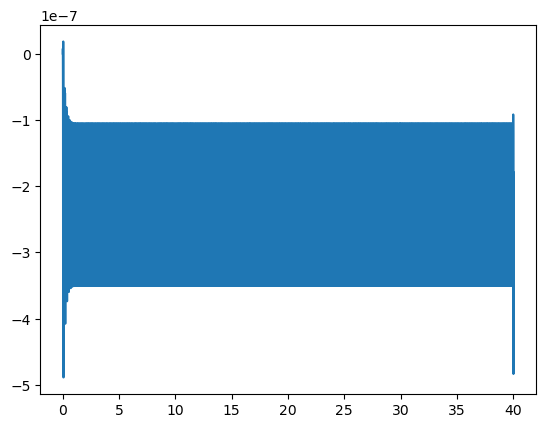

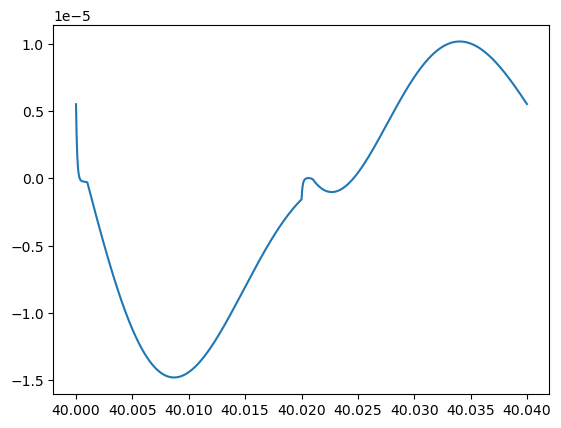

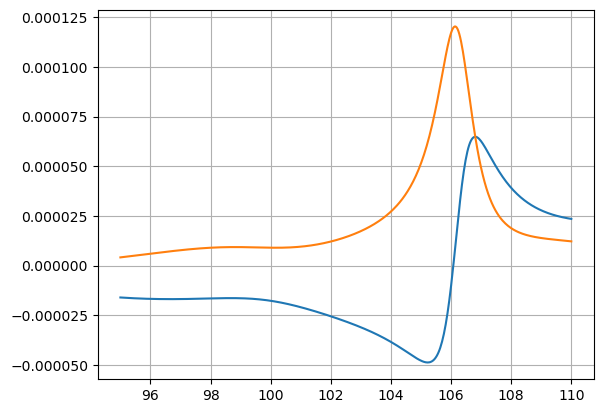

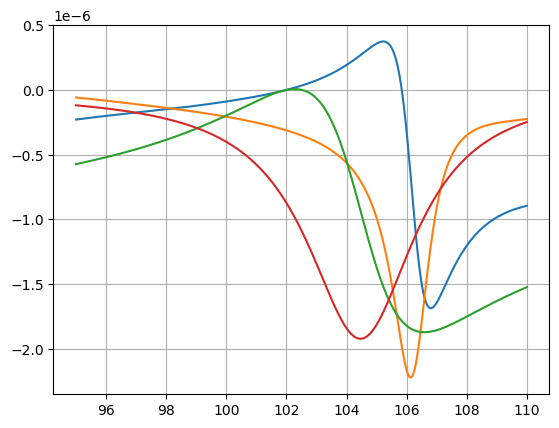

In [116]:
plt.plot(tSteps_nec[:], res_nec_om[:,3,10])
plt.figure()
plt.plot(tSteps_nec[endSlc], res_nec_b[endSlc,1,10])
plt.figure()
#plt.plot(-bias_ax,res_nec_om[endSlc,1,:].mean(axis=0))
plt.plot(-bias_ax,res_nec_om[endSlc,:2,:].mean(axis=0).T)
plt.grid()
plt.figure()
#plt.plot(-bias_ax,res_nec_om[endSlc,1,:].mean(axis=0))
plt.plot(-bias_ax,res_nec_om[endSlc,3:5,:].mean(axis=0).T)
plt.plot(-bias_ax,res_cw_om[endSlc,3:5,:].mean(axis=0).T)

plt.grid()


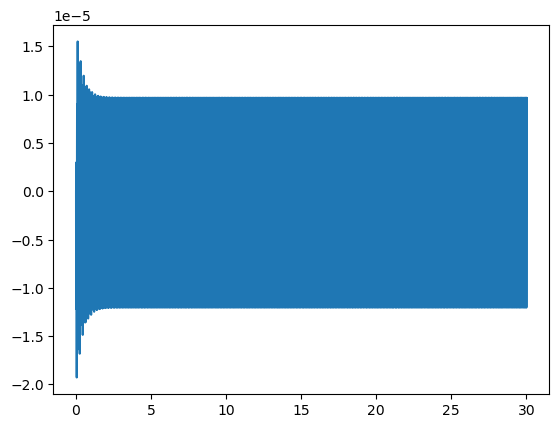

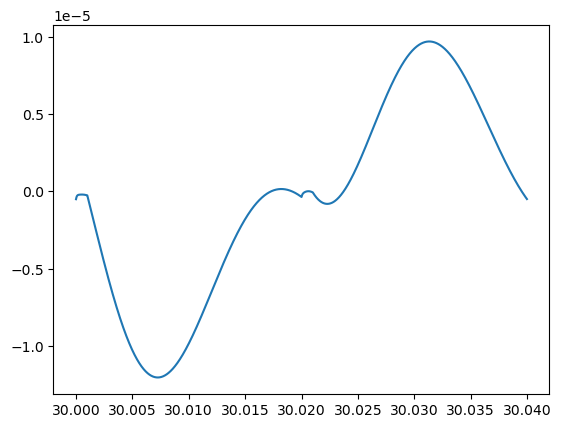

In [466]:
plt.plot(tSteps_nec[:], res_nec_b[:,1,7])
plt.figure()
plt.plot(tSteps_nec[endSlc], res_nec_b[endSlc,1,7])


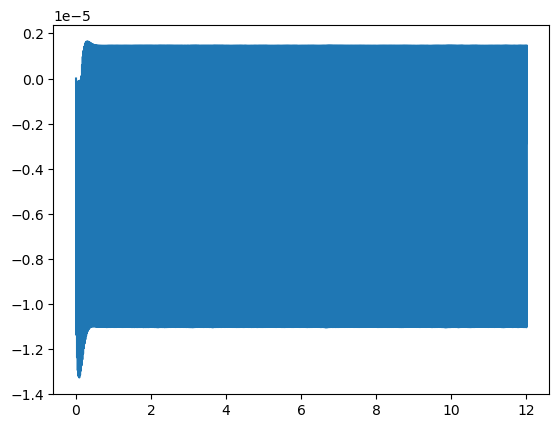

In [83]:
plt.plot(tSteps_nec, res_nec_b[:,1,4])


## fitting 

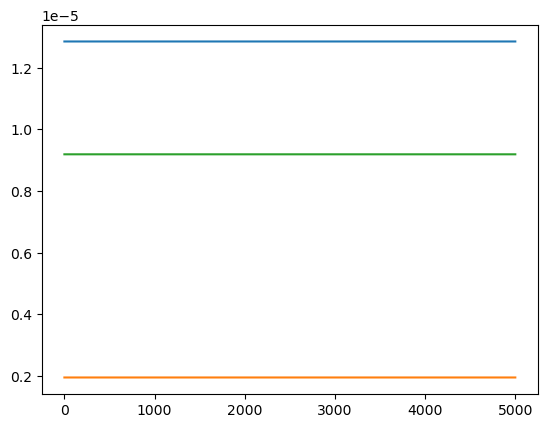

In [482]:
cw_sigs = res_cw_om[endSlc,:2,0]
plt.plot(cw_sigs)
plt.plot(np.sqrt(np.mean(cw_sigs**2, axis=1)))


In [42]:
endSlc = slice(-len(endSteps),None)
om_aloneL = []
b_aloneL = []
allL = []
all_individualL = []
cw_x_L = []
cw_y_L = []
cw_xb_L = []
cw_yb_L = []


for k in range(res_nec_b.shape[-1]):
    b_sigs = res_nec_b[endSlc,:2,k]
    om_sigs = res_nec_om[endSlc,:2,k]
    cw_sigs = res_cw_om[endSlc,:2,k]
    cw_b_sigs = res_cw_b[endSlc,:2,k]


    all_sigs = np.vstack([b_sigs.T, om_sigs.T])
    allL.append(fs.getVariances(all_sigs[[0,1,2,3]]))
    all_individualL.append([fs.getVariances(sig[None,:]).squeeze() for sig in all_sigs])
    cw_x_L.append(fs.getVariances( cw_sigs[:,:1].T ) )
    cw_y_L.append(fs.getVariances( cw_sigs[:,1:2].T ) )
    cw_xb_L.append(fs.getVariances( cw_b_sigs[:,:1].T ) )
    cw_yb_L.append(fs.getVariances( cw_b_sigs[:,1:2].T ) )


    om_aloneL.append(fs.getVariances(om_sigs.T))
    b_aloneL.append(fs.getVariances(b_sigs.T))

    #print(all_sigs.shape)
allL = np.array(allL)
all_individualL = np.array(all_individualL)
cw_x_L = np.array(cw_x_L)
cw_y_L = np.array(cw_y_L)
cw_xb_L = np.array(cw_xb_L)
cw_yb_L = np.array(cw_yb_L)

b_aloneL = np.array(b_aloneL)
om_aloneL = np.array(om_aloneL)


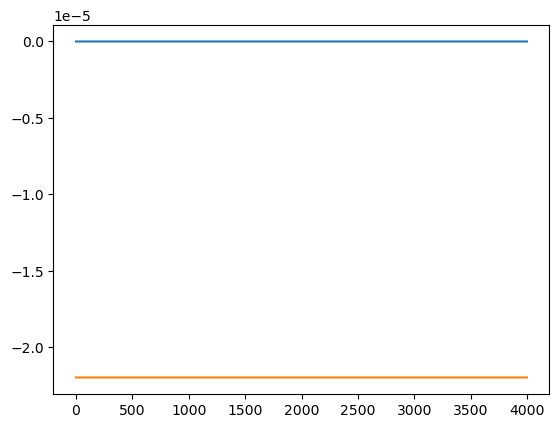

In [98]:
plt.plot(res_cw_alk[:,:2])


['#8dd3c7',
 '#feffb3',
 '#bfbbd9',
 '#fa8174',
 '#81b1d2',
 '#fdb462',
 '#b3de69',
 '#bc82bd',
 '#ccebc4',
 '#ffed6f']

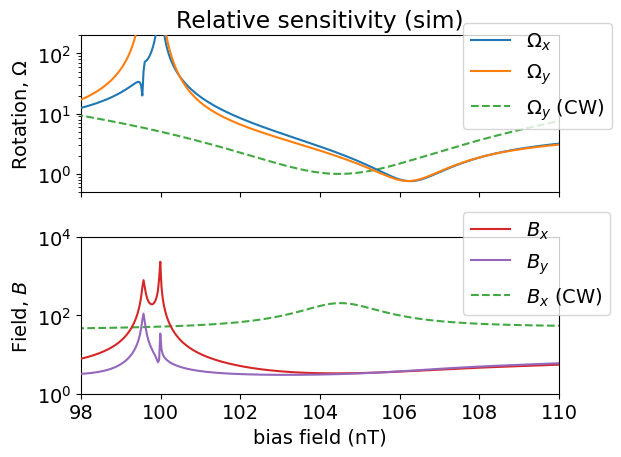

In [143]:
#plt.semilogy(-bias_ax,allL[:,-1:])
if 0:
    fig, (ax1,ax2) = plt.subplots(2,1, figsize=(10,10))
    ax1.semilogy(-bias_ax,om_aloneL)
    ax1.semilogy(-bias_ax,allL)
    ax2.semilogy(-bias_ax,all_individualL)
    
    alph = 1
    
    
    ax2.grid()
    ax1.grid()
alph = 0.9
fig, [ax1,ax2] = subplots(2,1, sharex=True)
pk = np.min(cw_y_L)**0.5
b_pk = np.sqrt(fs.getVariances([res_cw_alk[:,1]]))
ax1.semilogy(-bias_ax,np.sqrt(allL[:,2:])/pk, zorder=10)

#ax1.semilogy(-bias_ax, np.sqrt(cw_x_L)/pk, '--', alpha = alph)
ax1.semilogy(-bias_ax, np.sqrt(cw_y_L)/pk, '--', color = pltColors[2], alpha = alph, zorder=5)

ax2.semilogy(-bias_ax,np.sqrt(allL[:,0])/b_pk, color = pltColors[3], zorder=10)
ax2.semilogy(-bias_ax,np.sqrt(allL[:,1])/b_pk, color = pltColors[4], zorder=10)


ax2.semilogy(-bias_ax, np.sqrt(cw_xb_L)/b_pk, '--', color = pltColors[2], alpha = alph, zorder=0)
#ax2.semilogy(-bias_ax, np.sqrt(cw_yb_L)/b_pk, '--', alpha = alph)

#plt.ylim([5e1, 1e5])
#plt.semilogy(-bias_ax, cw_L)
ax1.set_ylim([0.5, 2e2])
#plt.figlegend(["X","Y", 'Y (CW)' ])
ax1.legend([r"$\Omega_x$",r"$\Omega_y$", r'$\Omega_y$ (CW)' ], loc=[0.8,0.4])
ax2.legend([r"$B_x$",r"$B_y$", r'$B_x$ (CW)'], loc=[0.8,0.5])


#plt.suptitle(r'$\lambda M_n P_n = 100$ nT, $\lambda M_a = 9$ nT ')
#ax1.grid()
#ax2.grid()
ax2.set_xlabel('bias field (nT)')
ax1.set_ylabel(r'Rotation, $\Omega$')
ax1.set_title('Relative sensitivity (sim)')
ax2.set_ylabel(r'Field, $B$')
#ax2.set_title('Relative B-field sensitivity')
ax2.set_ylim([1,1e4])
ax1.set_xlim([98, 110])
plt.tight_layout()

#plt.ylim([1e3,1e7])
#plt.savefig('sensitivity_vs_bias_model_v2.pdf')


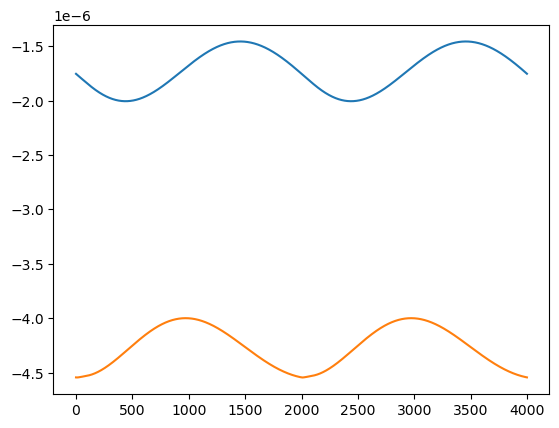

In [27]:
plt.plot(res_pul_om[endSlc,3:5,ind])


In [43]:
plt.hlines?


Signature:
plt.hlines(
    y: 'float | ArrayLike',
    xmin: 'float | ArrayLike',
    xmax: 'float | ArrayLike',
    colors: 'ColorType | Sequence[ColorType] | None' = None,
    linestyles: 'LineStyleType' = 'solid',
    label: 'str' = '',
    *,
    data=None,
    **kwargs,
) -> 'LineCollection'
Docstring:
Plot horizontal lines at each *y* from *xmin* to *xmax*.

Parameters
----------
y : float or array-like
    y-indexes where to plot the lines.

xmin, xmax : float or array-like
    Respective beginning and end of each line. If scalars are
    provided, all lines will have the same length.

colors : color or list of colors, default: :rc:`lines.color`

linestyles : {'solid', 'dashed', 'dashdot', 'dotted'}, default: 'solid'

label : str, default: ''

Returns
-------
`~matplotlib.collections.LineCollection`

Other Parameters
----------------
data : indexable object, optional
    If given, the following parameters also accept a string ``s``, which is
    interpreted as ``data[s]`` (unles

In [109]:
def plot_speed_alphas(x,y, ax=None, color='k', alpha_coeff=0.4, **kwargs):
    points = np.vstack([x,y]).T.reshape(-1,1,2)
    dLs = np.sqrt(np.sum((points[:-1] - points[1:])**2, axis = -1))[:,0]
    alphas = 1/dLs**alpha_coeff
    alphas/=alphas.max()
    segments = np.hstack((points[:-1], points[1:]))
    if ax is None:
        ax = plt.gca()
    for segment, alpha in zip(segments[::1], alphas):
        plt.plot(*segment.T, alpha=alpha,color=color,**kwargs)

#plot_varying_alphas(np.arange(100), np.arange(100)**2, np.sin(np.arange(100)/5)/2 +0.5)


In [163]:
np.savez("signatures_bias_106p25nT.npz", Bx = res_nec_b[endSlc,0,ind], By = -res_nec_b[endSlc,1,ind], Ox = res_nec_om[endSlc,0,ind], Oy = -res_nec_om[endSlc,1,ind]  )


In [168]:
!pwd


/home/morgan/pm/necom/sim


In [17]:
bias_ax.min(), bias_ax.max()


In [22]:
plot_speed_alphas?


Signature: plot_speed_alphas(x, y, ax=None, color='k', alpha_coeff=0.5, **kwargs)
Docstring: <no docstring>
File:      /tmp/ipykernel_16141/3929366978.py
Type:      function

<Figure size 640x480 with 0 Axes>

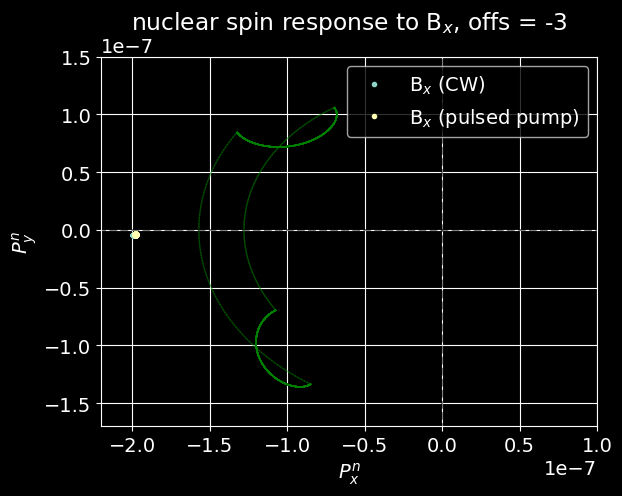

<Figure size 640x480 with 0 Axes>

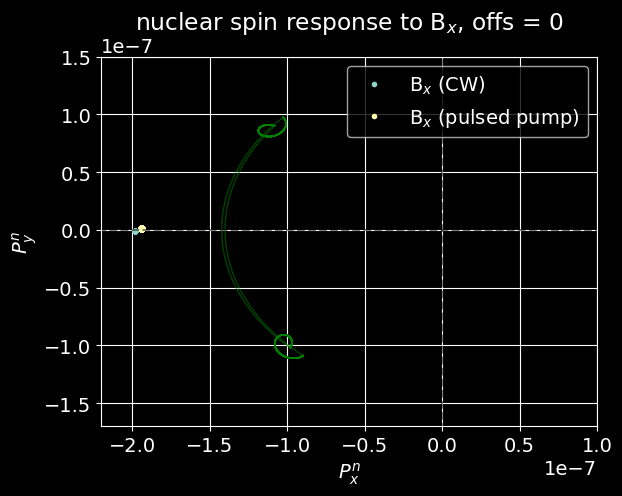

<Figure size 640x480 with 0 Axes>

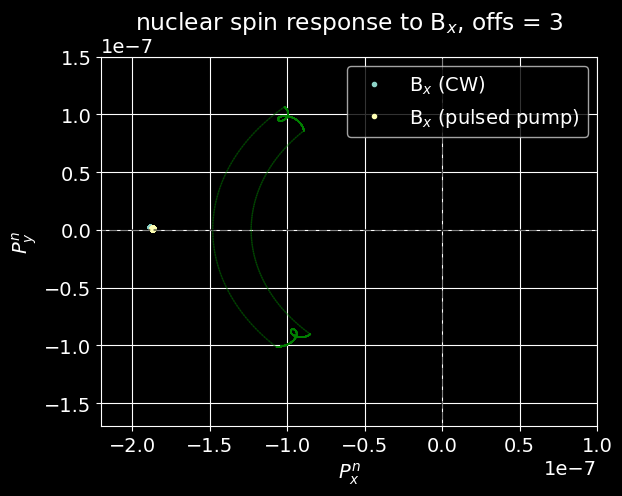

In [27]:
for bias_offs in [-3,0,3]:
    ind, ind_cw = (-bias_ax).searchsorted([106.25+bias_offs,104.5+bias_offs])
    plt.figure()
    
    #plt.plot(*res_nec_b[endSlc,3:5,ind].T, label = r'B$_x$ (pulsed pump, field)')
    plot_speed_alphas(*res_nec_b[endSlc,3:5,ind].T, alpha_coeff = .2,color='green', lw=1)
    plt.plot(*res_cw_b[endSlc,3:5,ind_cw].T, '.', label = r'B$_x$ (CW)')
    plt.plot(*res_pul_b[endSlc,3:5,ind].T, '.', label = r'B$_x$ (pulsed pump)')
    
    plt.hlines([0], -1,1, 'k','dashed', alpha=0.5)
    plt.vlines([0], -1,1, 'k','dashed', alpha=0.5)
    plt.legend()
    
    
    plt.xlim([-2.2e-7, 1e-7])
    plt.ylim([-1.7e-7, 1.5e-7])
    plt.title(fr'nuclear spin response to B$_x$, offs = {bias_offs} nT')
    
    plt.grid()
    plt.xlabel(r'$P^n_x$')
    plt.ylabel(r'$P^n_y$')



<Figure size 640x480 with 0 Axes>

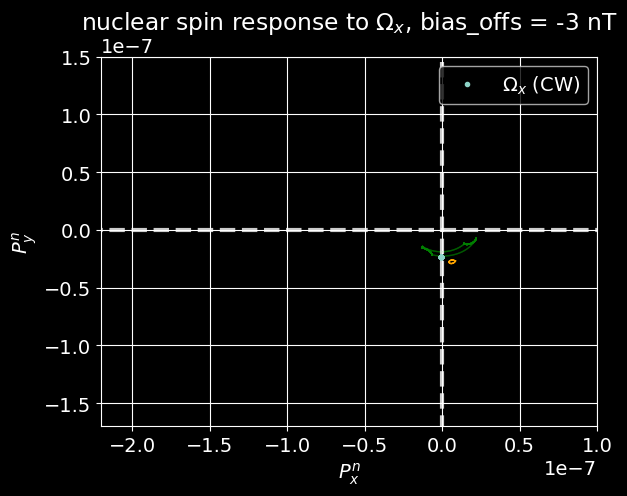

<Figure size 640x480 with 0 Axes>

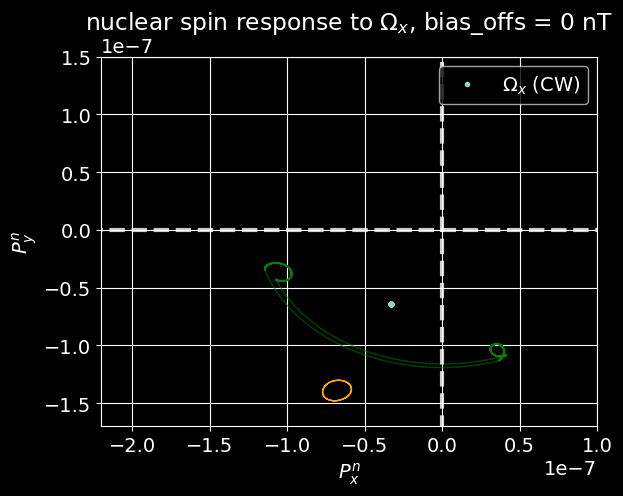

<Figure size 640x480 with 0 Axes>

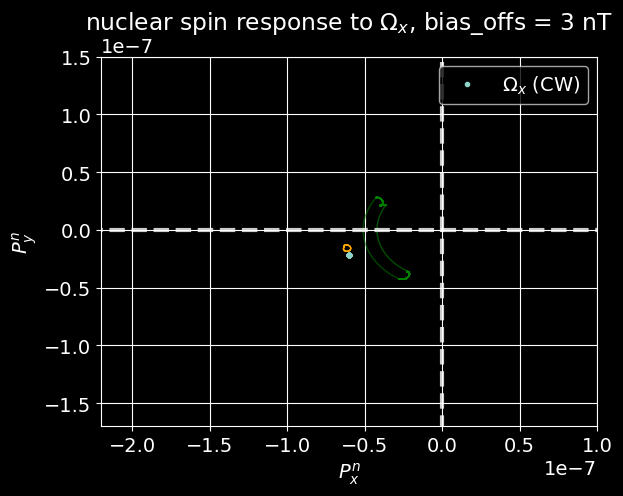

In [35]:
for bias_offs in [-3,0,3]:
    ind, ind_cw = (-bias_ax).searchsorted([106.25+bias_offs,104.5+bias_offs])
    plt.figure()
    #plt.plot(*res_pul_om[endSlc,3:5,ind].T/30, label = r'$\Omega_x$ (pulsed pump)')
    
    plot_speed_alphas(*res_nec_om[endSlc,3:5,ind].T/30, alpha_coeff=0.2,color='green', lw=1)# label = r'$\Omega_x$ (pulsed pump, field)')
    plt.plot(*res_cw_om[endSlc,3:5,ind_cw].T/30, '.', label = r'$\Omega_x$ (CW)')

    plt.plot(*res_pul_om[endSlc,3:5,ind].T/30, color='orange', lw=1)#, label = r'$\Omega_x$ (pulsed pump)')

    plt.hlines([0], -1,1, 'w','dashed', alpha=0.8, lw=3)
    plt.vlines([0], -1,1, 'w','dashed', alpha=0.8, lw=3)
    plt.legend()
    
    
    plt.xlim([-2.2e-7, 1e-7])
    plt.ylim([-1.7e-7, 1.5e-7])
    plt.title(fr'nuclear spin response to $\Omega_x$, bias_offs = {bias_offs} nT')
    
    plt.grid()
    plt.xlabel(r'$P^n_x$')
    plt.ylabel(r'$P^n_y$')


# Fit it

In [84]:
inds = np.hstack([np.arange(80, 2000), np.arange(2080, 4000)])
endSlc2 =  res_nec_b.shape[0]-4000 +inds
startSlc2 =  inds


In [97]:
bias_ax.shape


/tmp/ipykernel_16141/351764970.py:18: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  x1, r1, _, _ = lstsq(exog.T, om_x)
/tmp/ipykernel_16141/351764970.py:19: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  x2, r2, _, _ = lstsq(exog.T, om_y)


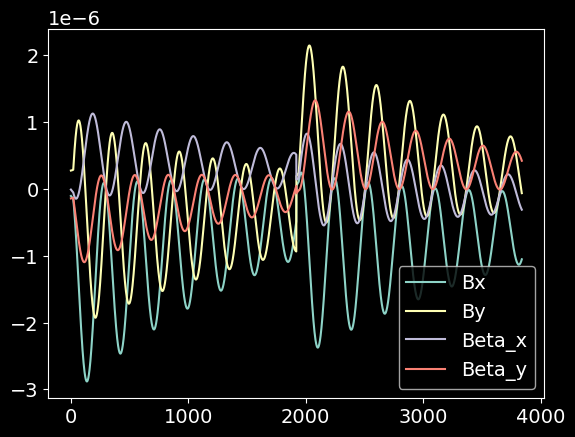

In [176]:
fit_p_L = []
r_L = []
recons_L = []
for ind in np.arange(bias_ax.size):
#for ind in [(-bias_ax).searchsorted(93)]:

#ind = (-bias_ax).searchsorted([106.25+bias_offs])
    
    mag_x, mag_y = res_nec_b[endSlc2, :2, ind].T
    mag_y = -mag_y
    fast_x, fast_y = res_nec_b[startSlc2, :2, ind].T
    fast_y = -fast_y
    beta_x, beta_y = mag_x - fast_x, mag_y - fast_y
    om_x, om_y = res_nec_om[endSlc2, :2, ind].T
    om_y = -om_y
    #plt.plot(res_nec_om[endSlc,0,ind])
    exog = np.vstack([mag_x, mag_y, beta_x, beta_y])
    x1, r1, _, _ = lstsq(exog.T, om_x)    
    x2, r2, _, _ = lstsq(exog.T, om_y)

    fit_p_L.append([x1,x2])
    r_L.append([r1,r2])
    recons1 = (x1[:,None]*exog).sum(axis=0)
    recons2 = (x2[:,None]*exog).sum(axis=0)

    recons_L.append([recons1, recons2, om_x,om_y])
    #exog = np.vstack([mag_x, mag_y, om_x, om_y])

fit_p_A = np.array(fit_p_L)
r_A = np.array(r_L)
if 1:
    exog.shape
    plt.plot(exog.T)
    plt.legend(['Bx', 'By', 'Beta_x', 'Beta_y'])


Text(0.5, 0, 'bias (nT)')

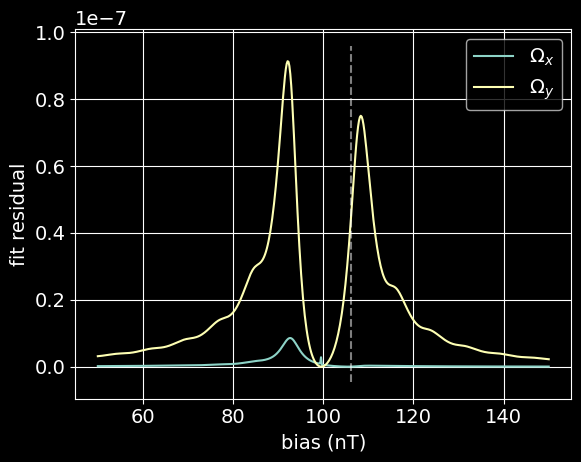

In [221]:
comp_ind = (-bias_ax).searchsorted(106.2) 
plt.plot(-bias_ax,r_A[:,0], label=r'$\Omega_x$')
plt.plot(-bias_ax,r_A[:,1], label=r'$\Omega_y$')
#plt.plot(-bias_ax[comp_ind], r_A[comp_ind,0], 'o') 
#plt.plot(-bias_ax[comp_ind], r_A[comp_ind,1], 'o') 
plt.vlines([106.25], *plt.gca().get_ylim(), ls='--', alpha=0.5)

plt.grid()
plt.legend()
plt.ylabel("fit residual")
plt.xlabel('bias (nT)')


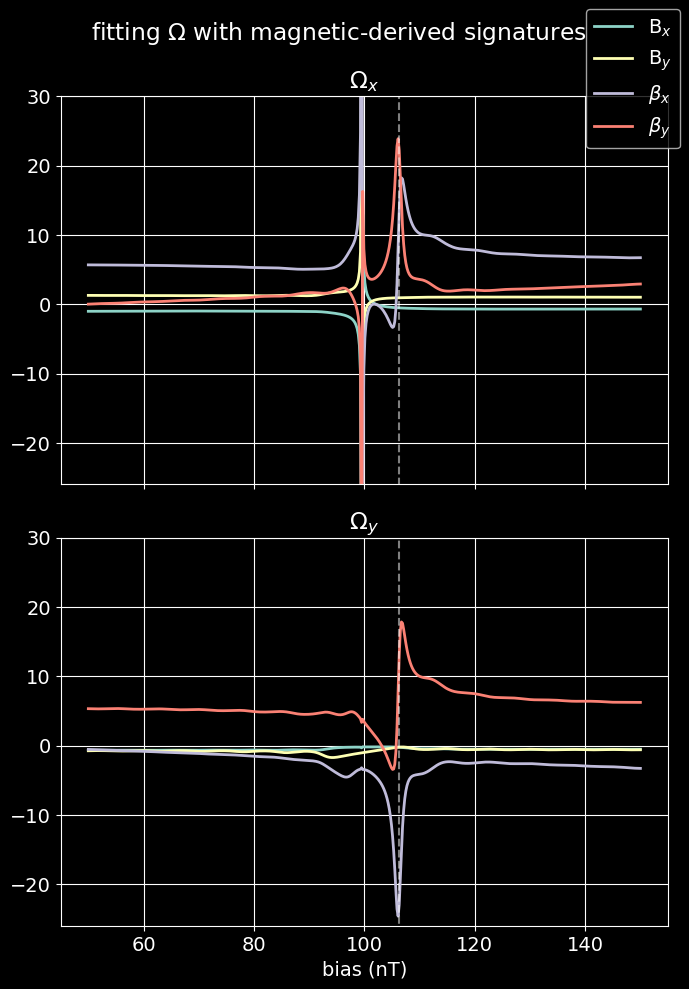

In [219]:
fig, (ax1, ax2) = plt.subplots(2,1, sharex=True, sharey = True, figsize=(7,10))
ax1.plot(-bias_ax,fit_p_A[:,0], lw=2)
ax2.plot(-bias_ax,fit_p_A[:,1], lw=2)
ax1.set_title(r'$\Omega_x$')
ax2.set_title(r'$\Omega_y$')
ax2.vlines(106.25, -50,50, ls='--', alpha=0.5)
ax1.vlines(106.25, -50,50, ls='--', alpha=0.5)
ax2.set_xlabel('bias (nT)')

ax1.grid()
ax2.grid()

ax1.set_ylim([-26,30])
plt.suptitle(r'fitting $\Omega$ with magnetic-derived signatures')
plt.figlegend([r"B$_x$",r"B$_y$",r"$\beta_x$",r"$\beta_y$"])
plt.tight_layout()


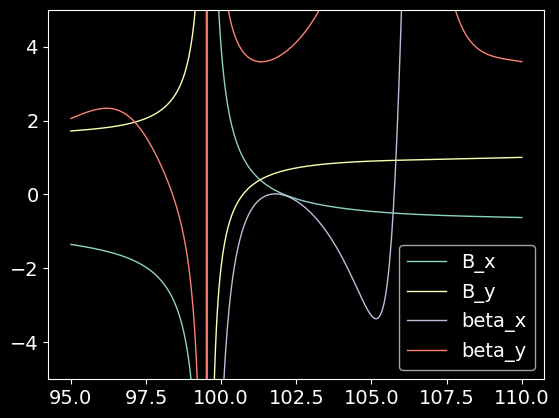

In [112]:
plt.plot(-bias_ax,fit_p_A[:, 0], lw=1)
plt.ylim([-5,5])
plt.legend(["B_x","B_y","beta_x","beta_y"])


In [182]:
comp_ind,ind


(281, 295)

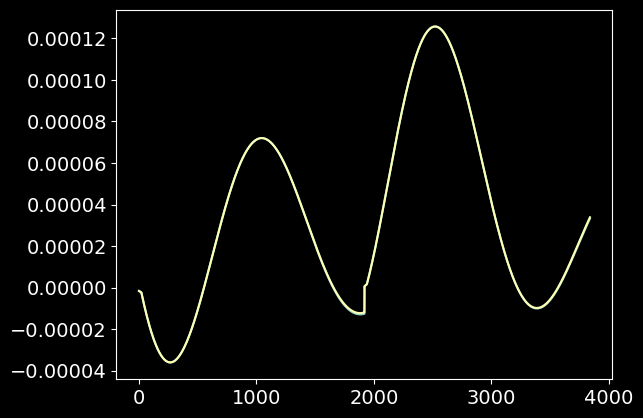

In [212]:
ind = comp_ind
ind = (-bias_ax).searchsorted(108.5)
plt.plot(recons_L[ind][0])
plt.plot(recons_L[ind][2])



In [233]:
axs


array([<Axes: >, <Axes: >], dtype=object)

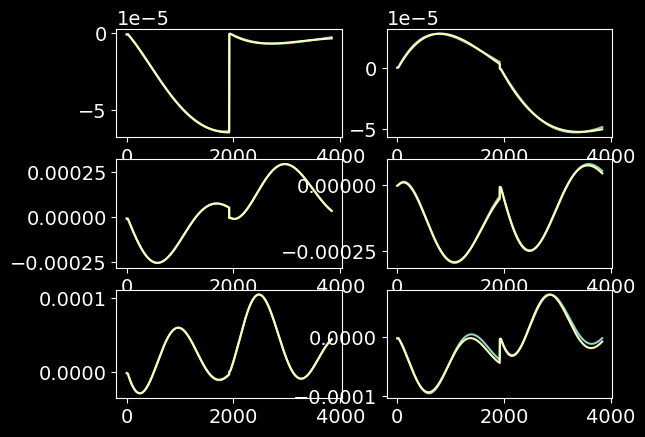

In [234]:
#x, _, _, _ = lstsq(exog.T, beta_x)
fig, axL = plt.subplots(3,2)
fields = [101.25, 106.25, 109.25]
tAx = np.arange(4000)
for field, axs in zip(fields, axL):
    ind = (-bias_ax).searchsorted(field)
    axs[0].plot(recons_L[ind][0])
    axs[0].plot(recons_L[ind][2])
    axs[1].plot(recons_L[ind][1])
    axs[1].plot(recons_L[ind][3])


    #axs[0][1].plot(recons_L[ind][1])



    #plt.plot(recons)
    #plt.plot(om_y)


In [116]:
r


array([2.95954829e-10])

In [115]:
x


array([-0.62394612,  1.00408866, 10.20292526,  3.59269882])

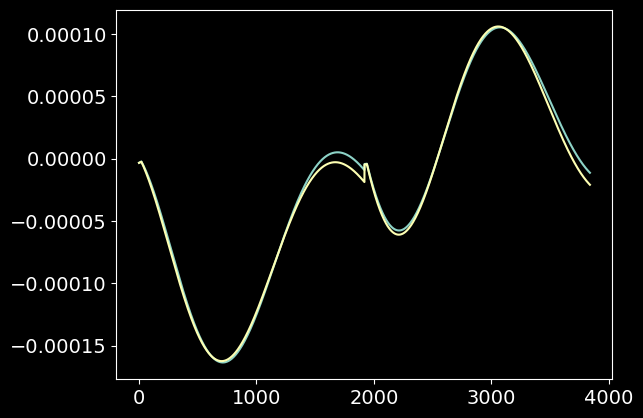

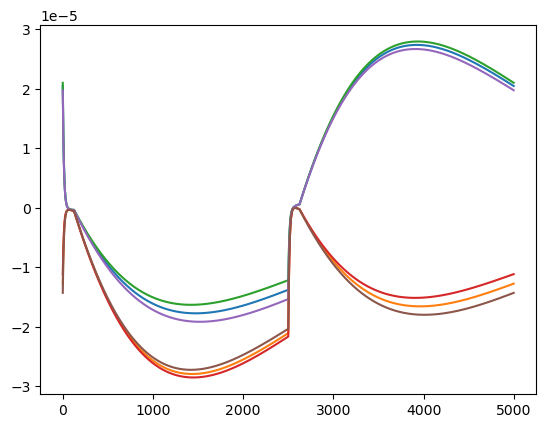

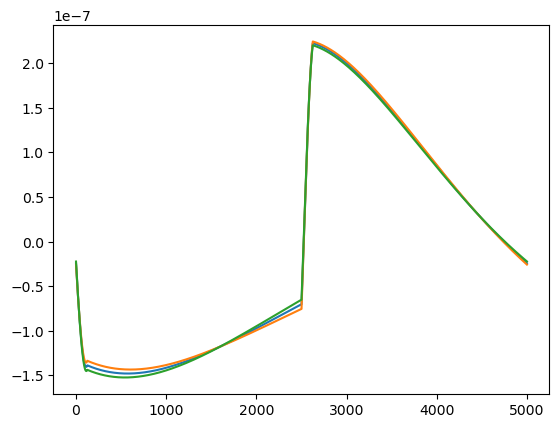

In [33]:
plt.plot(res_nec_b[endSlc,:2,153])
plt.plot(res_nec_b[endSlc,:2,150])
plt.plot(res_nec_b[endSlc,:2,156])
plt.figure()
plt.plot(res_nec_b[endSlc, 4,153])
plt.plot(res_nec_b[endSlc,4,150])
plt.plot(res_nec_b[endSlc,4,156])


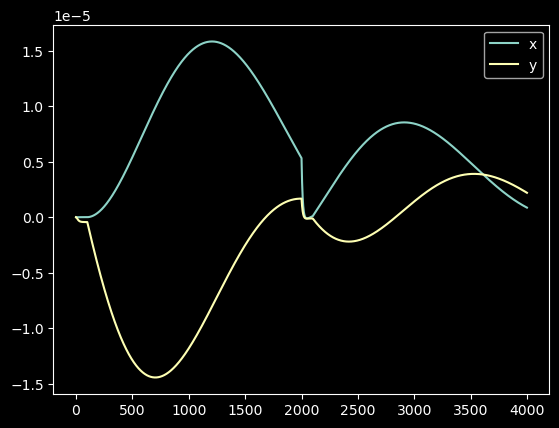

In [44]:
plt.plot(res_nec_b[startSlc,:2,0], label=['x','y'])
plt.legend()


In [33]:
np.vstack([sig_Bx, sig_By, sig_Ox, sig_Oy]).shape


# WOPM Plots

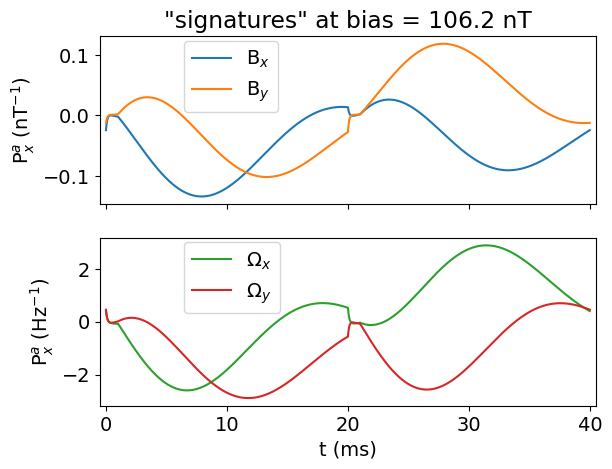

In [144]:

fig, (ax1,ax2)= plt.subplots(2,1, sharex=True)
#ax1.plot((endSteps-tEnd)*1000, res_nec_b[endSlc,:2,ind]/np.sqrt(np.mean(res_nec_b[endSlc,:2,ind]**2, axis=0)), label=['B$_x$', 'B$_y$'])
#ax1.plot((endSteps-tEnd)*1000, res_nec_om[endSlc,:2,ind]/np.sqrt(np.mean(res_nec_om[endSlc,:2,ind]**2, axis=0)), label=[r'$\Omega_x$', r'$\Omega_y$'])

sig_Bx =  res_nec_b[endSlc,0,ind]/1e-4#/np.sqrt(np.mean(res_nec_b[endSlc,0,ind]**2, axis=0))
sig_By =  -res_nec_b[endSlc,1,ind]/1e-4#/np.sqrt(np.mean(res_nec_b[endSlc,1,ind]**2, axis=0))
sig_Ox =  res_nec_om[endSlc,0,ind]/1e-4#/np.sqrt(np.mean(res_nec_om[endSlc,0,ind]**2, axis=0))
sig_Oy =  -res_nec_om[endSlc,1,ind]/1e-4#/np.sqrt(np.mean(res_nec_om[endSlc,1,ind]**2, axis=0))

sig_Beta_y = -(res_nec_b[endSlc,0,ind]-res_nec_b[startSlc,0,ind]) /np.sqrt(np.mean(res_nec_b[endSlc,0,ind]**2, axis=0))
sig_Beta_x = -(res_nec_b[endSlc,1,ind]-res_nec_b[startSlc,1,ind]) /np.sqrt(np.mean(res_nec_b[endSlc,0,ind]**2, axis=0))



ax1.plot((endSteps-tEnd)*1000, np.vstack([sig_Bx, sig_By]).T, label=['B$_x$', 'B$_y$'])#, r'$\Omega_x$', r'$\Omega_y$'])
ax2.plot((endSteps-tEnd)*1000, np.vstack([sig_Ox])[0], label=r'$\Omega_x$', color = pltColors[2])
ax2.plot((endSteps-tEnd)*1000, np.vstack([sig_Oy])[0], label=r'$\Omega_y$', color = pltColors[3])

#ax3.plot((endSteps-tEnd)*1000, np.vstack([sig_Beta_x, sig_Beta_y]).T, label=[r'$\Omega_x$', r'$\Omega_y$'])


ax2.set_xlabel('t (ms)')
ax1.legend(loc=[0.17,.55])
ax1.set_ylabel(r'P$^a_x$ (nT$^{-1})$')
ax1.set_title('"signatures" at bias = 106.2 nT')
ax2.legend(loc=[0.17,0.55])
ax2.set_ylabel(r'P$^a_x$ (Hz$^{-1})$')
ax1.set_xlim([-0.5, 40.5])
#plt.savefig('simulated_signatures_K_He_v2.pdf')


In [ ]:
### plt.semilogy(-bias_ax,allL[:,-1:])
fig, (ax1,ax2) = plt.subplots(2,1, figsize=(10,10))
ax1.semilogy(-bias_ax,om_aloneL)
ax1.semilogy(-bias_ax,allL)


ax2.semilogy(-bias_ax,all_individualL)




ax2.grid()
ax1.grid()
fig, [ax1,ax2] = subplots(2,1, sharex=True)
pk = np.min(cw_y_L)**0.5
ax1.semilogy(-bias_ax,np.sqrt(allL[:,2:])/pk, zorder=10)

ax1.semilogy(-bias_ax, np.sqrt(cw_x_L)/pk)
ax1.semilogy(-bias_ax, np.sqrt(cw_y_L)/pk)

ax2.semilogy(-bias_ax,np.sqrt(allL[:,:2])/pk)

ax2.semilogy(-bias_ax, np.sqrt(cw_xb_L)/pk)
ax2.semilogy(-bias_ax, np.sqrt(cw_yb_L)/pk)
#plt.ylim([5e1, 1e5])
#plt.semilogy(-bias_ax, cw_L)
ax1.set_ylim([0.5, 2e2])
plt.figlegend(["X","Y", r"X (CW)", 'Y (CW)' ])
plt.suptitle('Relative sensitivity')
ax1.grid()
ax2.grid()
ax2.set_xlabel('bias field (nT)')
ax1.set_ylabel(r'Rotation, $\Omega$')
ax2.set_ylabel(r'Field, $B$')

ax1.set_xlim([95, 110])
#plt.ylim([1e3,1e7])


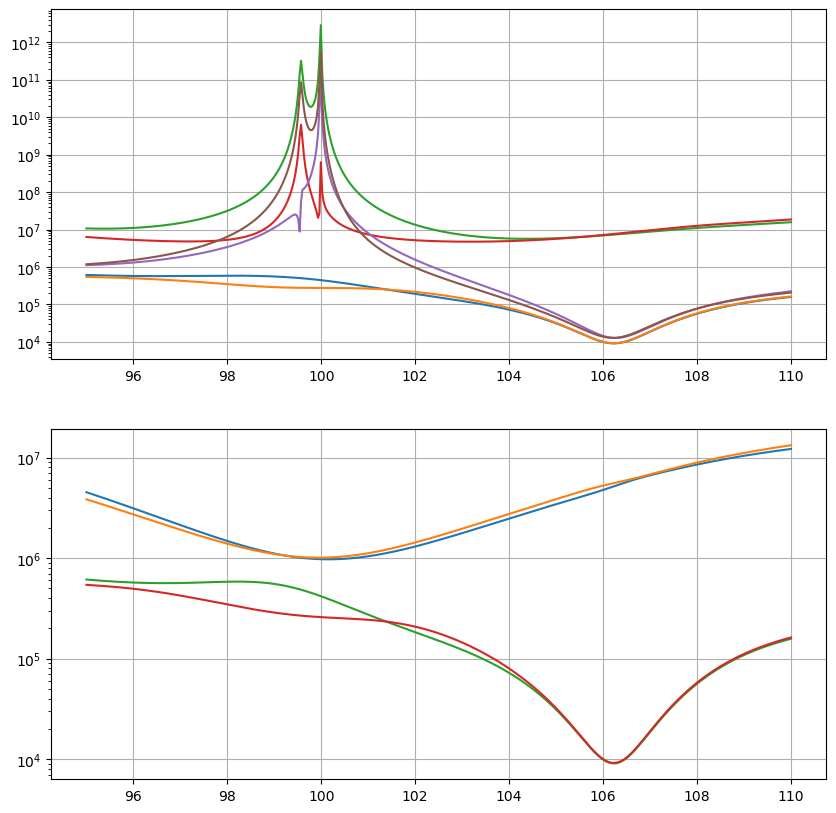

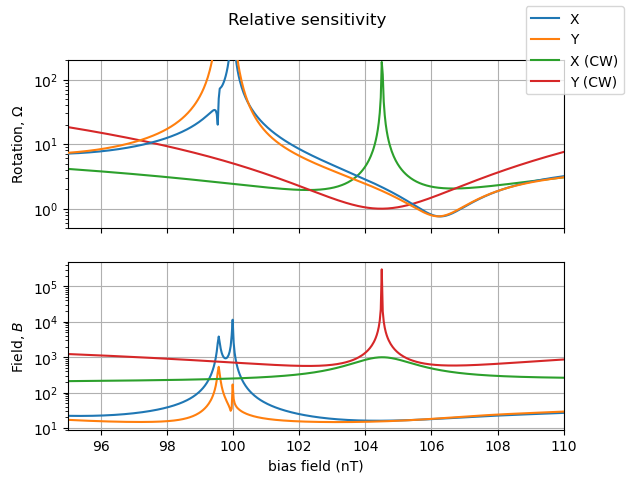

In [93]:
#plt.semilogy(-bias_ax,allL[:,-1:])
fig, (ax1,ax2) = plt.subplots(2,1, figsize=(10,10))
ax1.semilogy(-bias_ax,om_aloneL)
ax1.semilogy(-bias_ax,allL)


ax2.semilogy(-bias_ax,all_individualL)




ax2.grid()
ax1.grid()
fig, [ax1,ax2] = subplots(2,1, sharex=True)
pk = np.min(cw_y_L)**0.5
ax1.semilogy(-bias_ax,np.sqrt(allL[:,2:])/pk, zorder=10)

ax1.semilogy(-bias_ax, np.sqrt(cw_x_L)/pk)
ax1.semilogy(-bias_ax, np.sqrt(cw_y_L)/pk)

ax2.semilogy(-bias_ax,np.sqrt(allL[:,:2])/pk)

ax2.semilogy(-bias_ax, np.sqrt(cw_xb_L)/pk)
ax2.semilogy(-bias_ax, np.sqrt(cw_yb_L)/pk)
#plt.ylim([5e1, 1e5])
#plt.semilogy(-bias_ax, cw_L)
ax1.set_ylim([0.5, 2e2])
plt.figlegend(["X","Y", r"X (CW)", 'Y (CW)' ])
plt.suptitle('Relative sensitivity')
ax1.grid()
ax2.grid()
ax2.set_xlabel('bias field (nT)')
ax1.set_ylabel(r'Rotation, $\Omega$')
ax2.set_ylabel(r'Field, $B$')

ax1.set_xlim([95, 110])
#plt.ylim([1e3,1e7])


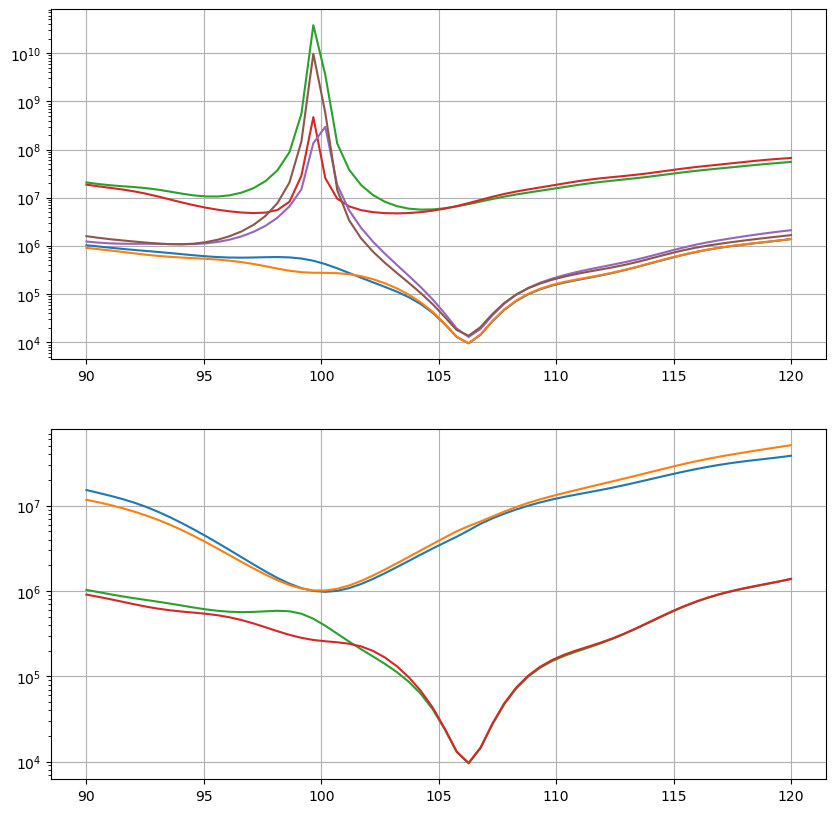

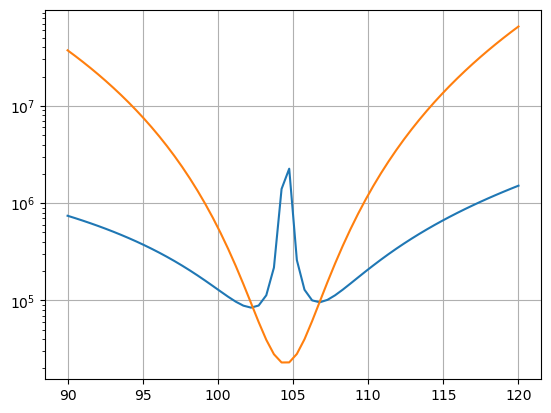

In [468]:
#plt.semilogy(-bias_ax,allL[:,-1:])
fig, (ax1,ax2) = plt.subplots(2,1, figsize=(10,10))
ax1.semilogy(-bias_ax,om_aloneL)
ax1.semilogy(-bias_ax,allL)

ax2.semilogy(-bias_ax,all_individualL)


ax2.grid()
ax1.grid()
plt.figure()
plt.semilogy(-bias_ax, cw_x_L)
plt.semilogy(-bias_ax, cw_y_L)
plt.grid()
#plt.ylim([1e3,1e7])


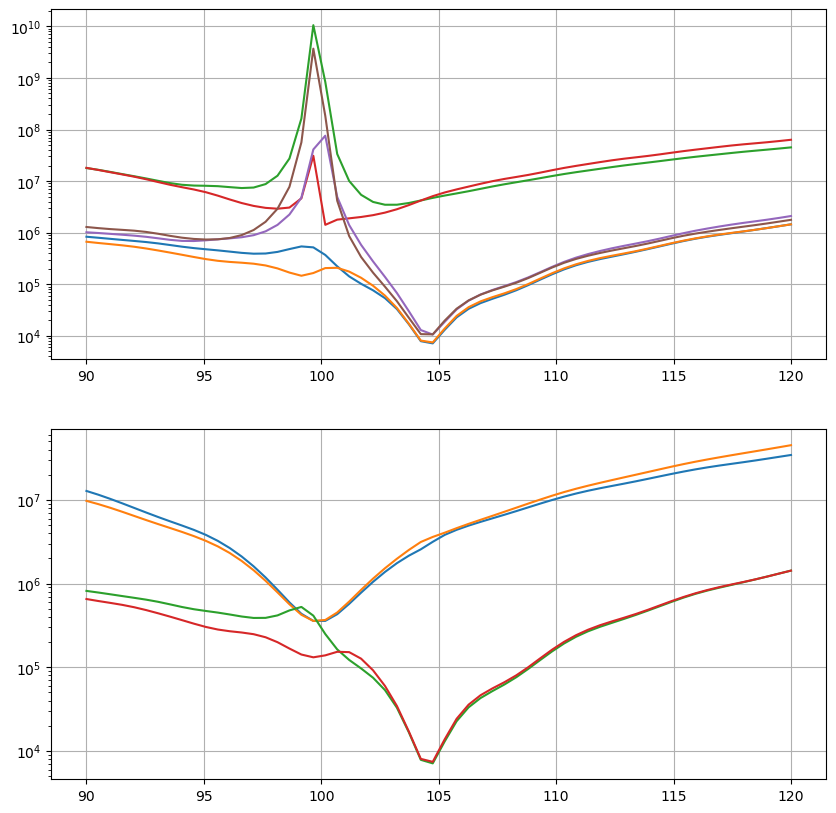

In [439]:
#plt.semilogy(-bias_ax,allL[:,-1:])
fig, (ax1,ax2) = plt.subplots(2,1, figsize=(10,10))
ax1.semilogy(-bias_ax,om_aloneL)
ax1.semilogy(-bias_ax,allL)

ax2.semilogy(-bias_ax,all_individualL)
ax2.grid()
ax1.grid()
#plt.ylim([1e3,1e7])


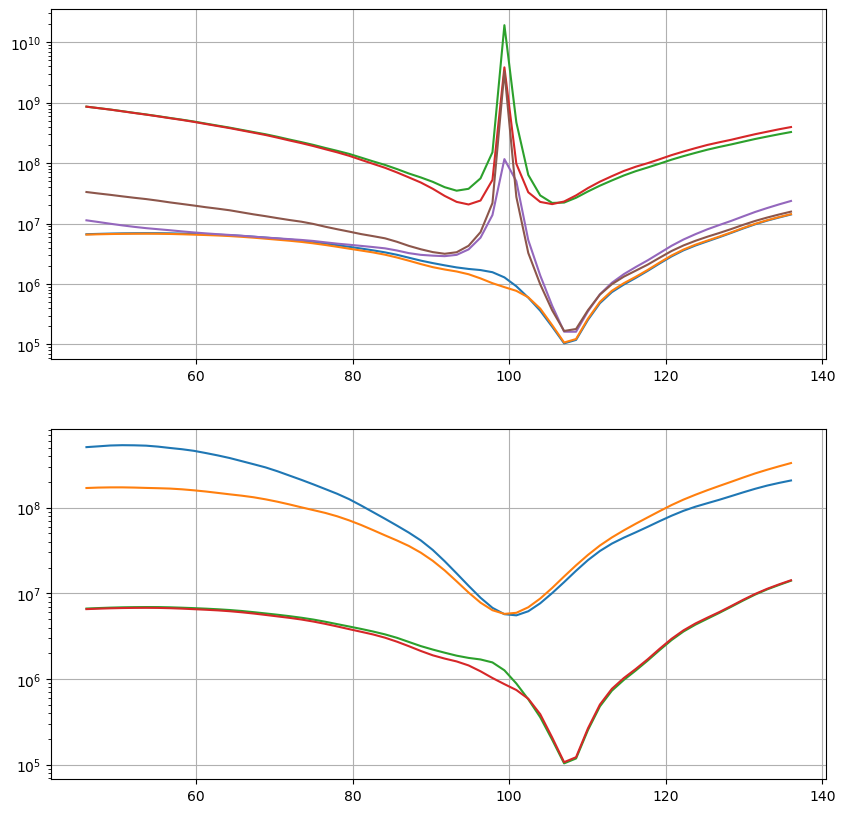

In [401]:
#plt.semilogy(-bias_ax,allL[:,-1:])
fig, (ax1,ax2) = plt.subplots(2,1, figsize=(10,10))
ax1.semilogy(-bias_ax,om_aloneL)
ax1.semilogy(-bias_ax,allL)

ax2.semilogy(-bias_ax,all_individualL)
ax2.grid()
ax1.grid()
#plt.ylim([1e3,1e7])


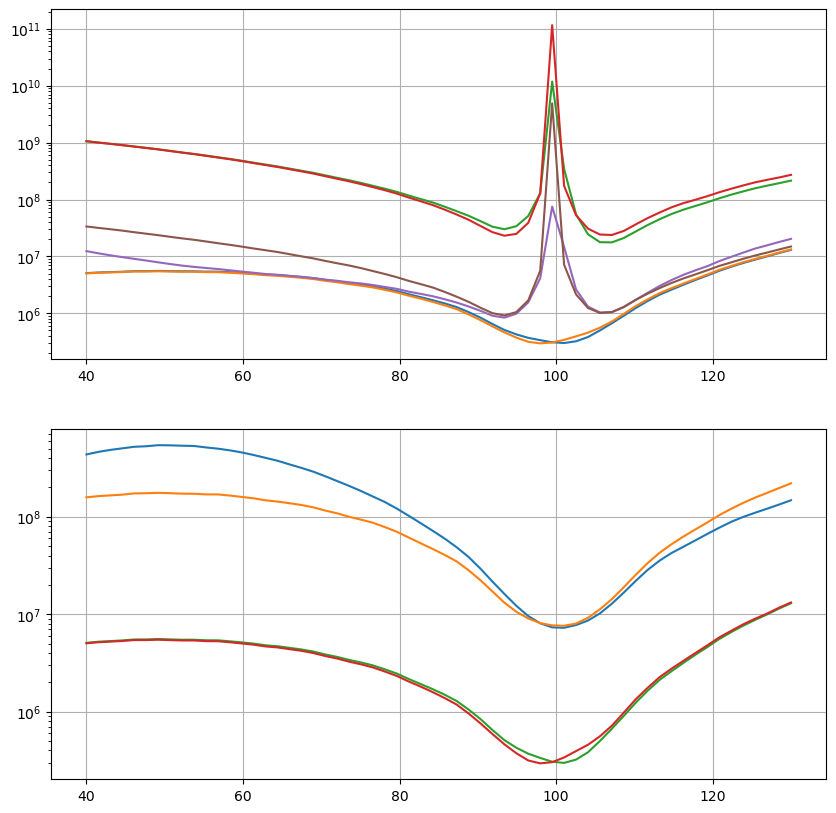

In [395]:
#plt.semilogy(-bias_ax,allL[:,-1:])
fig, (ax1,ax2) = plt.subplots(2,1, figsize=(10,10))
ax1.semilogy(-bias_ax,om_aloneL)
ax1.semilogy(-bias_ax,allL)

ax2.semilogy(-bias_ax,all_individualL)
ax2.grid()
ax1.grid()
#plt.ylim([1e3,1e7])


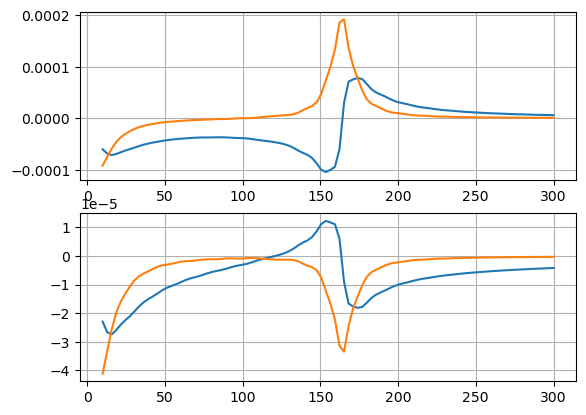

In [187]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_nec[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_nec[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


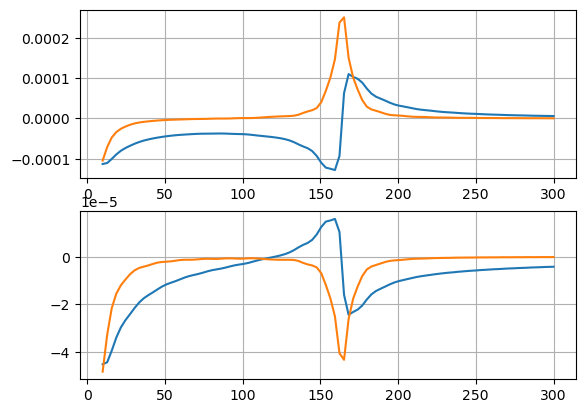

In [182]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_nec[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_nec[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


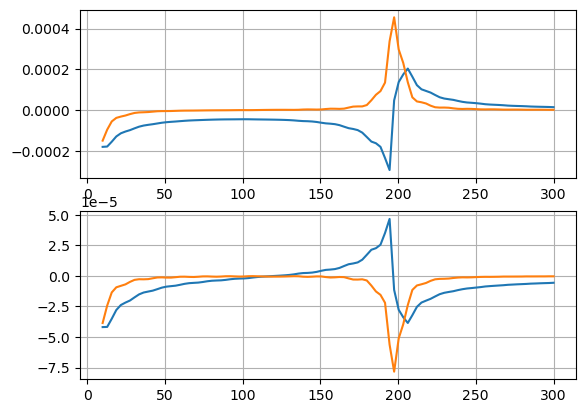

In [173]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_nec[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_nec[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


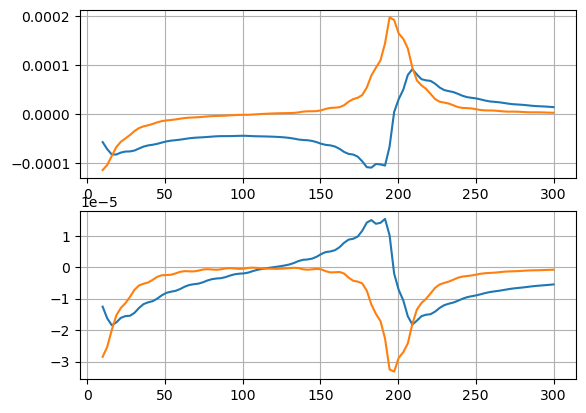

In [167]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_nec[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_nec[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


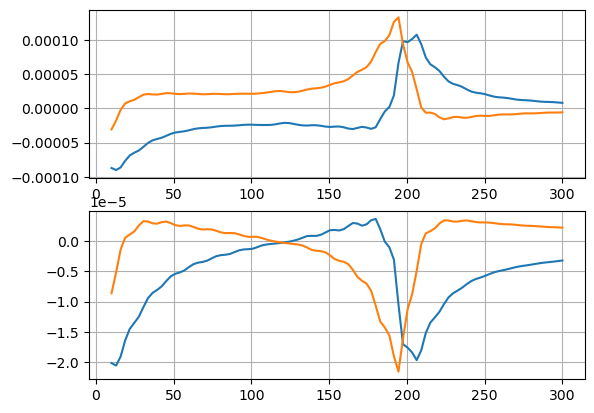

In [163]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_nec[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_nec[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


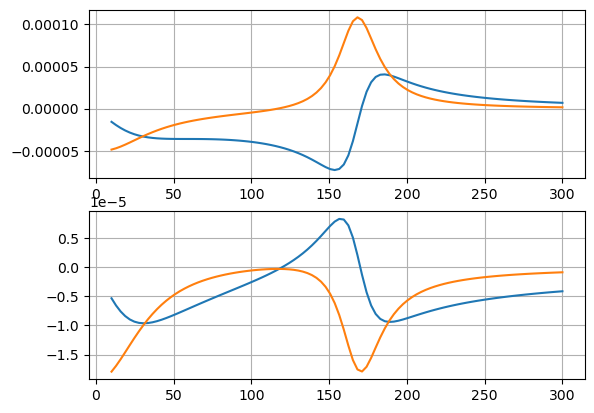

In [168]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_cw[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_cw[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


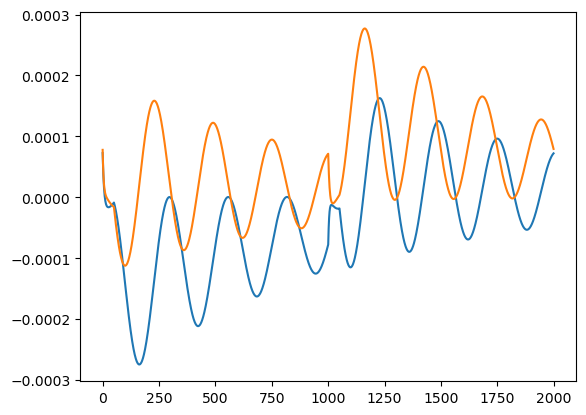

In [368]:
plt.plot(results_nec[startInd:,:2, 84])


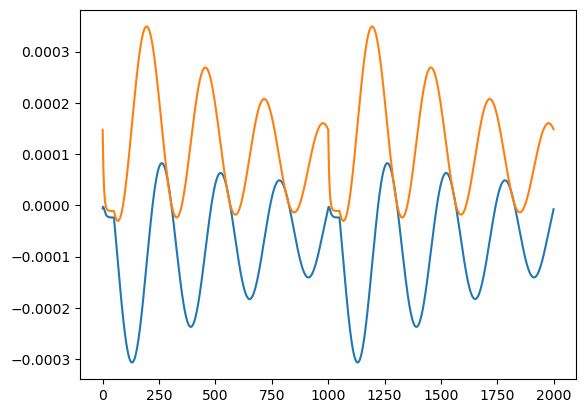

In [366]:
plt.plot(results_nec[startInd:,:2, 84])


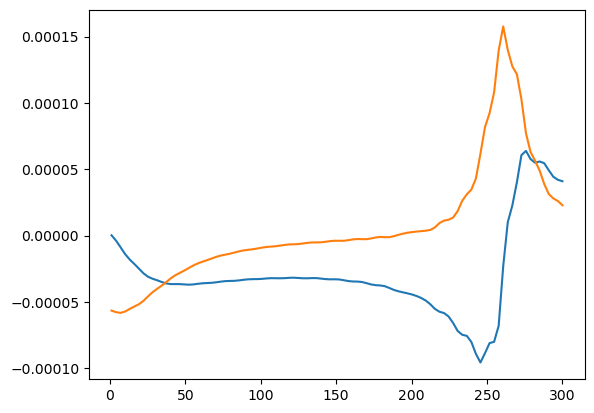

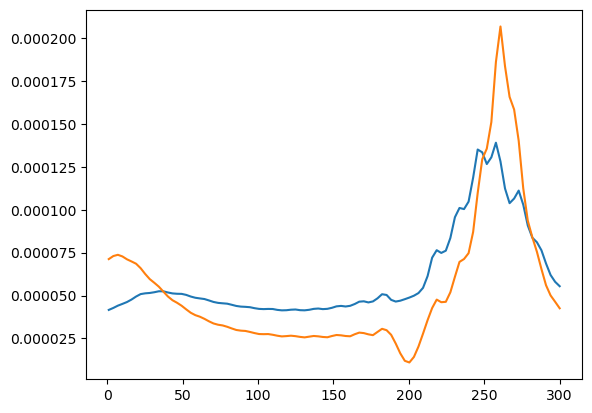

In [358]:
startInd = tSteps.searchsorted(6)
plt.plot(-bias_ax,results_nec[startInd:,:2].mean(axis=0).T)
plt.figure()
plt.plot(-bias_ax,np.sqrt(np.mean(results_nec[startInd:,:2]**2, axis=0)).T)


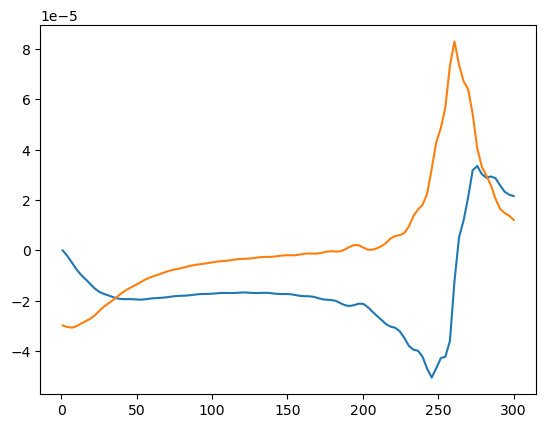

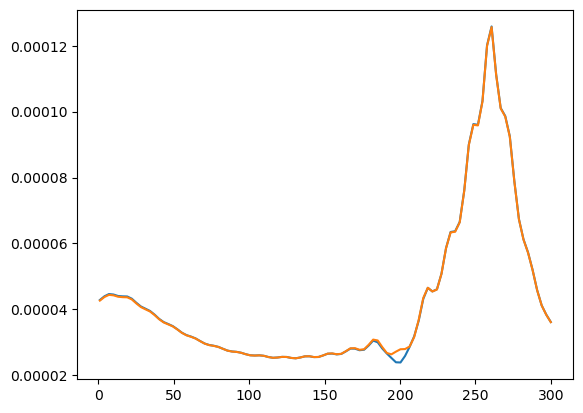

In [354]:
startInd = tSteps.searchsorted(6)
plt.plot(-bias_ax,results_nec[startInd:,:2].mean(axis=0).T)
plt.figure()
plt.plot(-bias_ax,np.sqrt(np.mean(results_nec[startInd:,:2]**2, axis=0)).T)


In [349]:
bias_ax[83]


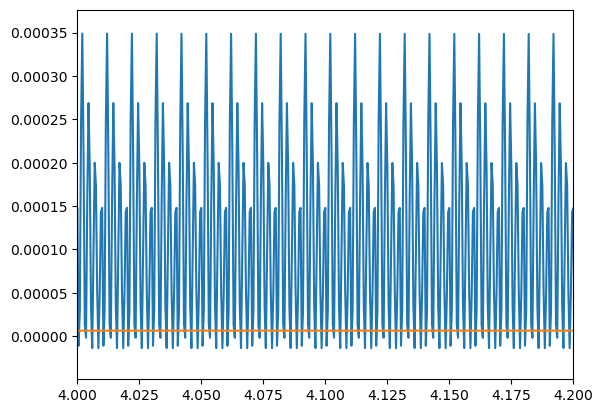

In [364]:
k = 84
plt.plot(tSteps, results_nec[:,[1,3], k])


plt.xlim([4,4.2])


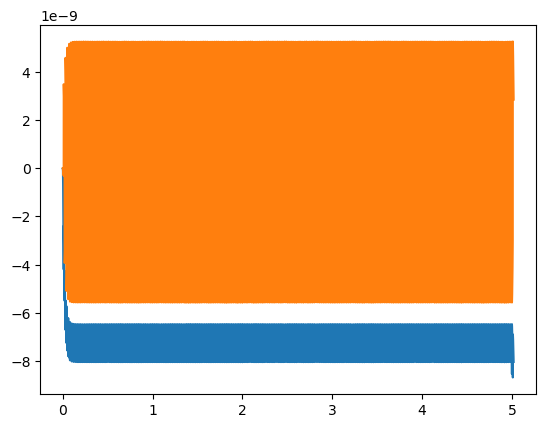

In [278]:
plt.plot(tSteps, results_nec[:,3, 0])
plt.plot(tSteps, results_nec[:,4, 0])

#plt.xlim([0,4])


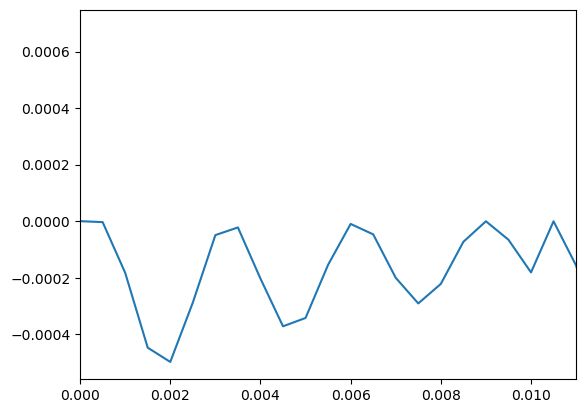

In [165]:
plt.plot(tSteps, results_alk[:,0, 1])
plt.xlim([0.00,0.011])


In [168]:
results_alk[:,2, 1].mean(axis=0)


# CW

In [217]:
tau = 0.01
ode_s.set_driving({
                   s.Rp:subD[s.R_e_sd],#m.make_repeating_pulse_func(period= tau,rel_width=0.05, pulse_area=10),
                   s.anom_n_v[2]:0,#m.make_alternating_pulse_func(period=tau, rel_width=0.05, pulse_area=1*pi/3, gamma = constantsD[s.y_n]),
                   s.B_v[0]: 0e-4,
                    s.B_v[1]: 0e-4,
                   s.Om_v[0]: 1e-4,
                  })
tEnd = 60
model = ode_s.setup_model(solver_opts={'max_step': 0.00025}, bForceStateDimensions=False)
tSteps = np.arange(0, tEnd, 0.0005)
tSteps = np.hstack([tSteps, tEnd+np.arange(0,2*tau, 0.00001)])
%time results_cw =model.integrate(tSteps)
#results_alk/= (bias_ax[None,None]*1e-4)


CPU times: user 35.4 s, sys: 425 ms, total: 35.8 s
Wall time: 35.7 s


In [152]:
bias_ax[14]


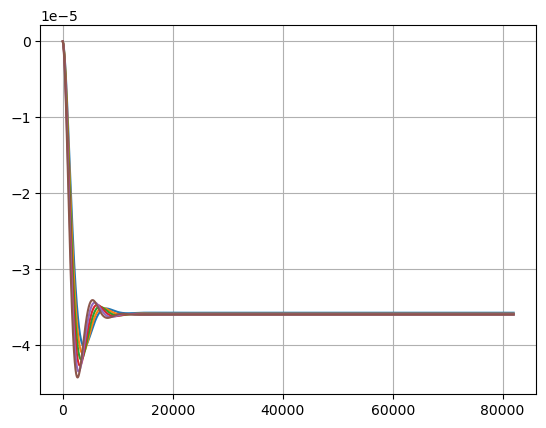

In [153]:
plt.plot(results_cw[:,0, 12:18])
plt.grid()
#plt.xlim([0,100])


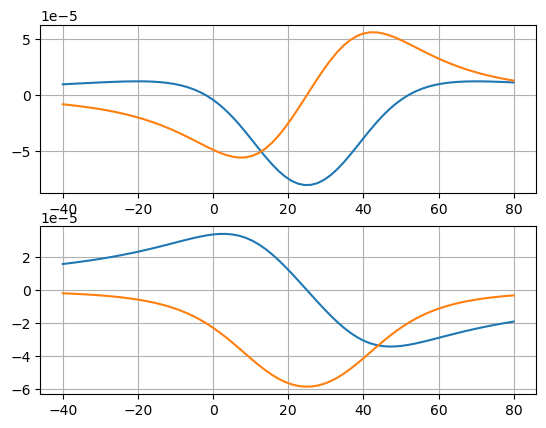

In [218]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_cw[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_cw[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


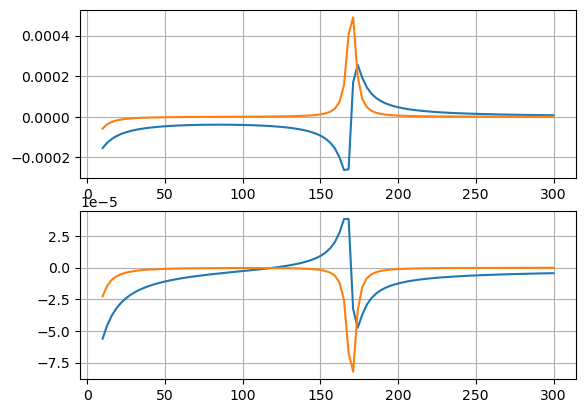

In [144]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_cw[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_cw[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


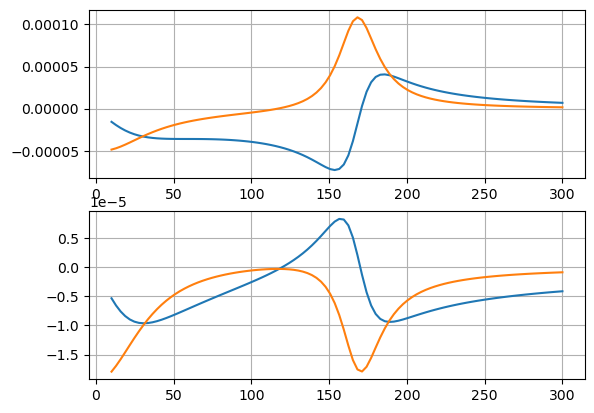

In [154]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_cw[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_cw[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


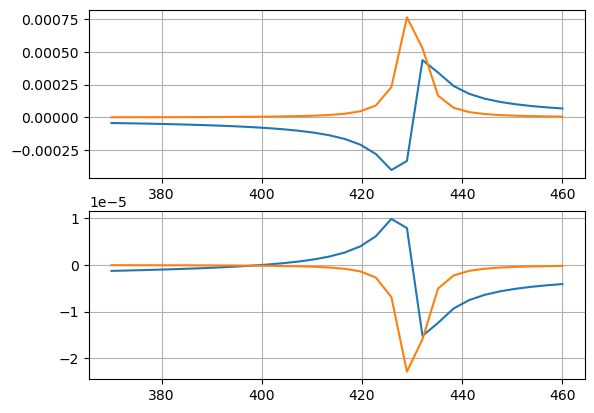

In [111]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_cw[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_cw[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


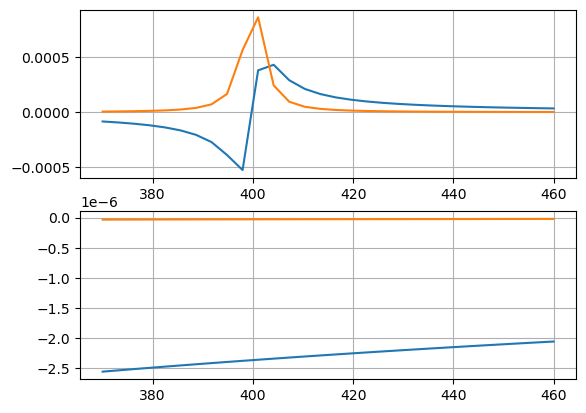

In [117]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_cw[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_cw[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


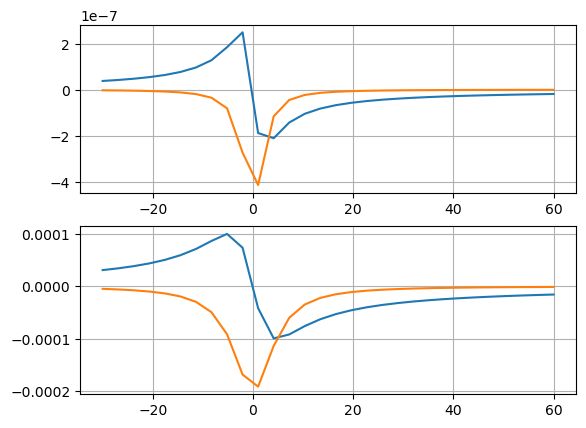

In [126]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_cw[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_cw[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


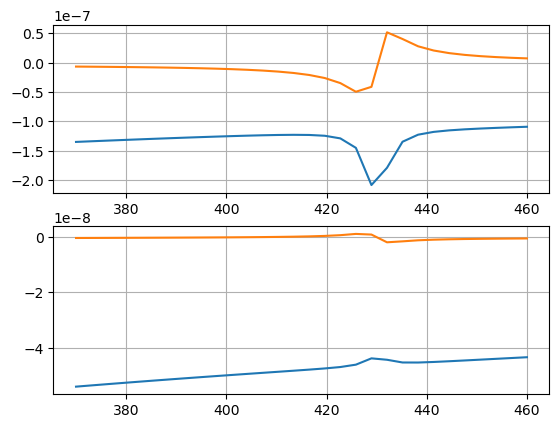

In [109]:
fit,(ax1,ax2) = subplots(2,1)
ax1.plot(-bias_ax, results_cw[-1000:,:2,:].mean(axis=0).T )
ax1.grid()
ax2.plot(-bias_ax, results_cw[-1000:,3:5,:].mean(axis=0).T )
ax2.grid()
#plt.ylim([-0.00001,0.00001])
#plt.ylim([-0.00001,0.00001])


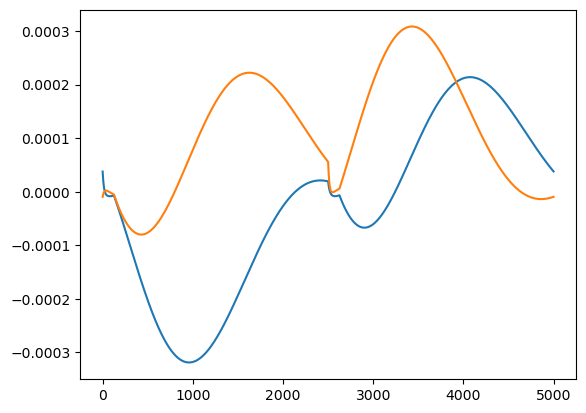

In [19]:
(-bias_ax).searchsorted(105)


333

In [18]:
bias_ax.min()


In [21]:
1/(5*7)
